# Agri EdgeAI Research — Mango Leaf Disease Classification (v5)

**Pipeline thị giác máy tính cổ điển có khả năng giải thích cho bệnh lá xoài**

Phiên bản này tập trung vào một hệ sinh thái dữ liệu: **MangoLeafBD (8 lớp)** làm tập nguồn và **MLDID (5 lớp chung)** làm kiểm thử ngoài. Các bản sửa v5 tập trung vào độ bền với nhiễu, tiền xử lý nhận biết tiền cảnh, chọn ngưỡng confidence nhất quán với validation, benchmark transfer-learning có đóng băng backbone, và căn chỉnh miền CORAL theo từng khối đặc trưng.

**Nguyên tắc thực nghiệm**
- Group-Split theo cụm gần-trùng là kết quả chính; Random-Split chỉ là phép tham chiếu có nguy cơ rò rỉ.
- Threshold/gate và checkpoint CNN được chọn trên validation; test chỉ dùng để báo cáo.
- Bảng 5 là đánh giá robustness trên các phép biến đổi tổng hợp; không khẳng định trước hệ thống sẽ thắng mọi perturbation.
- Bảng 6 đo latency CPU thực tế; các phép đo proxy trong bảng ablation được ghi rõ là ước lượng.
- MLDID zero-shot không dùng nhãn/statistics target để huấn luyện hoặc căn chỉnh. CORAL dùng đặc trưng target không nhãn nên được ghi rõ là transductive.
- Các chỉ số từ HTML phiên v4 là kết quả lịch sử, không được sao chép thành kết quả v5; hãy chạy lại notebook trước khi dùng trong paper.


## 1. Cấu trúc Google Drive

Gốc dữ liệu: `/content/drive/MyDrive/Agri_EdgeAI_Research/`

```text
Agri_EdgeAI_Research/
└── MANGO/
    ├── main_data/
    │   └── MangoLeafBD Dataset.zip
    └── external_data/
        └── Raw Images of Five Class (Resized).zip
```

Notebook giải nén ZIP vào SSD tạm `/content/agri_edgeai_ssd/MANGO/`, không sửa dữ liệu nguồn trên Drive. Sau giải nén, nó dò thư mục dataset theo các tên root đã xác nhận. Nếu Drive đã chứa thư mục giải nén, notebook cũng hỗ trợ sao chép sang SSD.

**Lưu ý về cache:** v5 thay đổi thuật toán tiền xử lý/LBP/CORAL. Feature cache được tăng phiên bản để buộc trích xuất lại các vector tương thích.


## 2. Khởi tạo môi trường
Thư viện, cấu hình random seed và trạng thái runtime. Google Drive được mount nếu notebook đang chạy trong Colab.


In [ ]:
# ==============================================================================
# CELL 0 — KHỞI TẠO MÔI TRƯỜNG, THƯ VIỆN VÀ SEED TÁI LẬP
# ==============================================================================
import os
import re
import cv2
import time
import json
import glob
import math
import shutil
import zipfile
import warnings
import traceback
import gc
from concurrent.futures import ThreadPoolExecutor
import psutil
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm.auto import tqdm
from IPython.display import display, Markdown
from scipy.stats import binomtest
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
    confusion_matrix, classification_report, f1_score,
    precision_recall_curve, auc
)

warnings.filterwarnings("ignore", category=FutureWarning)

# Google Colab: mount Drive only if it is not already mounted.
try:
    from google.colab import drive
    if not os.path.exists("/content/drive/MyDrive"):
        drive.mount("/content/drive")
except ImportError:
    print("[INFO] Non-Colab environment detected; Drive mounting skipped.")

SEED = 20261022
np.random.seed(SEED)
try:
    cv2.setNumThreads(1)
except Exception:
    pass
print(f"[INIT OK] Environment ready | Seed={SEED} | OpenCV={cv2.__version__}")


Mounted at /content/drive
[INIT OK] Environment ready | Seed=20261022 | OpenCV=5.0.0


## 3. Cấu hình nghiên cứu chuyên sâu — MANGO

| Vai trò | Dataset | Quy mô dự kiến | Sử dụng |
|---|---|---:|---|
| Tập nguồn | MangoLeafBD Dataset | 8 lớp, khoảng 4.000 ảnh | Group-Split, kiểm toán near-duplicate, ablation, robustness, benchmark |
| Tập kiểm thử ngoài | Raw Images of Five Class (Resized) / MLDID | 5 lớp chung, khoảng 3.000 ảnh | Đánh giá cross-dataset trên các nhãn giao nhau |

Tám lớp nguồn được chuẩn hóa thành `Anthracnose`, `Bacterial_Canker`, `Cutting_Weevil`, `Die_Back`, `Gall_Midge`, `Healthy`, `Powdery_Mildew` và `Sooty_Mold`. Tên `Sooty Mould`/`Sooty Mold` và `Gall Mid` ở external được ánh xạ có quy tắc về nhãn chuẩn. Bảng 7 chỉ sử dụng năm nhãn chung; không giả định external có ba lớp mà nguồn còn lại.

CNN benchmark bật mặc định ở bản đơn-track này, nhưng tổng thời gian phụ thuộc runtime, tải pretrained weights và khả năng GPU. Mạng được train trên GPU nếu có, sau đó latency inference được đo trên CPU để so sánh với pipeline cổ điển.


In [ ]:
# -----------------------------------------------------------------------------
# MỤC 2 — CẤU HÌNH ĐƠN TRACK: BỆNH LÁ XOÀI (MangoLeafBD + MLDID)
# -----------------------------------------------------------------------------
BASE_DRIVE_DIR = "/content/drive/MyDrive/Agri_EdgeAI_Research"
LOCAL_SSD_BASE = "/content/agri_edgeai_ssd"
VALID_EXTS = {".jpg", ".jpeg", ".jpe", ".png", ".bmp", ".webp", ".tif", ".tiff"}

TRACKS = [{
    "track_name": "MANGO",
    "drive_folder": "MANGO",
    "main_source_role": "main_data",
    "main_root_hints": [["MangoLeafBD Dataset"]],
    "external_root_hints": [["Resize mango leaf disease"]],
    "expected_class_count": 8,
    "main_dataset": "MangoLeafBD Dataset (8 classes, ~4,000 images)",
    "external_dataset": "Raw Images of Five Class (Resized) / MLDID (5 shared classes, ~3,000 images)",
}]
TRACK_FOLDER_MAP = {t["track_name"]: t["drive_folder"] for t in TRACKS}

RUN_BACKGROUND_SHORTCUT_AUDIT = True
RUN_CNN_BENCHMARK = True
CNN_EPOCHS = 6
CNN_MODELS = ["mobilenet_v3_small", "mobilenet_v2", "resnet50"]
CNN_LATENCY_SAMPLE_LIMIT = 300
FEATURE_EXTRACTION_WORKERS = min(4, max(1, os.cpu_count() or 1))

# Bump both values whenever a feature formula, preprocessing path, or split schema changes.
MANIFEST_SCHEMA_VERSION = "manifest-v6-mango-mad-lut-fastfg-blockcoral"
FEATURE_CACHE_VERSION = "handcrafted-v8-mango-mad-lut-fastfg-blockcoral"
CANONICAL_COLOR_MODE = "lab_l"  # lab_l preserves leaf chroma; gray_world_bounded is an optional sensitivity check.

os.makedirs(BASE_DRIVE_DIR, exist_ok=True)
os.makedirs(LOCAL_SSD_BASE, exist_ok=True)
print("Focused paper track:", [t["track_name"] for t in TRACKS])
print("Google Drive:", BASE_DRIVE_DIR)
print("Local SSD:", LOCAL_SSD_BASE)
print("CNN benchmark:", RUN_CNN_BENCHMARK, "| epochs/model:", CNN_EPOCHS)


Focused paper track: ['MANGO']
Google Drive: /content/drive/MyDrive/Agri_EdgeAI_Research
Local SSD: /content/agri_edgeai_ssd
CNN benchmark: True | epochs/model: 6


## 4. Chuẩn bị dữ liệu — giải nén ZIP vào SSD Colab

Cell kế tiếp chỉ xử lý hai vị trí của MANGO (`main_data` và `external_data`). Mỗi ZIP được giải nén vào một thư mục theo tên archive; marker cho phép bỏ qua việc giải nén lại nếu file nguồn không đổi. Các file nguồn trên Google Drive được giữ nguyên.


In [ ]:
# -----------------------------------------------------------------------------
# MỤC 3 — NẠP / GIẢI NÉN ZIP VÀO SSD COLAB (MỘT CELL CHO CẢ 6 VỊ TRÍ)
# -----------------------------------------------------------------------------
# Mỗi ZIP được giải nén vào:
# /content/agri_edgeai_ssd/<DATASET>/<main_data|external_data>/<ZIP_STEM>/
# Marker tương thích với lần giải nén trước để không giải nén lại nếu archive
# và đích không thay đổi. Các file nguồn trên Drive không bị sửa.

def _count_images_quick(folder):
    count = 0
    if not os.path.isdir(folder):
        return 0
    for root, _, files in os.walk(folder):
        count += sum(
            1 for name in files
            if not name.startswith(".") and os.path.splitext(name)[1].lower() in VALID_EXTS
        )
    return count

def _safe_extract_zip(zip_path, destination):
    destination_abs = os.path.abspath(destination)
    with zipfile.ZipFile(zip_path, "r") as zf:
        # Reject archive traversal entries before extracting.
        for member in zf.infolist():
            target = os.path.abspath(os.path.join(destination, member.filename))
            if os.path.commonpath([destination_abs, target]) != destination_abs:
                raise RuntimeError(f"Unsafe path inside ZIP: {member.filename}")
        zf.extractall(destination)

roles_to_prepare = sorted({
    (cfg["drive_folder"], role)
    for cfg in TRACKS
    for role in ("main_data", "external_data")
})

for drive_folder, role in roles_to_prepare:
    drive_dir = os.path.join(BASE_DRIVE_DIR, drive_folder, role)
    local_root = os.path.join(LOCAL_SSD_BASE, drive_folder, role)

    if not os.path.isdir(drive_dir):
        print(f"[DATA SOURCE MISSING] {drive_dir}")
        continue

    zip_paths = sorted(glob.glob(os.path.join(drive_dir, "*.zip")))
    if zip_paths:
        os.makedirs(local_root, exist_ok=True)
        for zip_path in zip_paths:
            stem = os.path.splitext(os.path.basename(zip_path))[0]
            dest = os.path.join(local_root, stem)
            marker = os.path.join(dest, ".unzip_complete")
            expected_marker = (
                f"archive={zip_path}\n"
                f"size={os.path.getsize(zip_path)}\n"
                f"mtime={os.path.getmtime(zip_path)}\n"
            )

            marker_matches = False
            if os.path.isfile(marker):
                try:
                    marker_matches = (
                        open(marker, "r", encoding="utf-8").read() == expected_marker
                        and _count_images_quick(dest) > 0
                    )
                except OSError:
                    marker_matches = False

            if marker_matches:
                print(f"[ZIP SKIP] {drive_folder}/{role}/{os.path.basename(zip_path)} (unchanged)")
                continue

            if os.path.isdir(dest):
                shutil.rmtree(dest)

            os.makedirs(dest, exist_ok=True)
            print(f"[ZIP EXTRACT] {drive_folder}/{role}/{os.path.basename(zip_path)}")
            _safe_extract_zip(zip_path, dest)

            with open(marker, "w", encoding="utf-8") as f:
                f.write(expected_marker)

            print(f"[ZIP READY] {_count_images_quick(dest):,} image files -> {dest}")
    else:
        # Also support folders that were manually extracted on Drive.
        existing_local_count = _count_images_quick(local_root)
        drive_count = _count_images_quick(drive_dir)
        if existing_local_count:
            print(f"[LOCAL READY] {local_root} | {existing_local_count:,} image files")
        elif drive_count:
            shutil.copytree(drive_dir, local_root, dirs_exist_ok=True)
            print(f"[COPY TO SSD] {drive_folder}/{role} | {drive_count:,} image files")
        else:
            print(f"[NO ZIP OR IMAGES] {drive_dir}")

print("[DATA PREPARATION COMPLETE] Exact dataset roots will be resolved in the next section.")


[ZIP EXTRACT] MANGO/external_data/Raw Images of Five Class (Resized).zip
[ZIP READY] 3,000 image files -> /content/agri_edgeai_ssd/MANGO/external_data/Raw Images of Five Class (Resized)
[ZIP EXTRACT] MANGO/main_data/MangoLeafBD Dataset.zip
[ZIP READY] 4,000 image files -> /content/agri_edgeai_ssd/MANGO/main_data/MangoLeafBD Dataset
[DATA PREPARATION COMPLETE] Exact dataset roots will be resolved in the next section.


## 5. Ánh xạ nhãn theo folder MANGO

Nhãn được đọc từ tên folder lớp dọc theo đường dẫn tương đối. `Train`, `Test`, `Val` và tên dataset không được xem là nhãn. Các folder `Augmented`, `Balanced` hoặc component chỉ rõ augmentation bị loại khỏi scan của tập nguồn chính; ảnh gần trùng trong các folder lớp vẫn được xử lý bằng kiểm toán pHash/HSV và Group-Split.

Các tên lớp được chuẩn hóa rõ ràng; nhãn external không thuộc tám lớp chuẩn sẽ bị loại khỏi phép đo. Bảng 7 sử dụng phần giao nhãn nguồn–đích và ghi riêng số lớp dùng để đánh giá.


In [ ]:
# -----------------------------------------------------------------------------
# MỤC 4.1 — CHUẨN HÓA NHÃN THEO CẤU TRÚC THỰC TẾ CỦA TỪNG DATASET
# -----------------------------------------------------------------------------
def _norm_token(value):
    """Normalize a folder name for matching, while retaining original names in manifests."""
    value = str(value).strip().casefold()
    value = value.replace("&", " and ")
    value = re.sub(r"[^a-z0-9]+", "_", value)
    return re.sub(r"_+", "_", value).strip("_")


GENERIC_DIRS = {
    "", "main_data", "external_data", "original", "originals", "raw", "raw_data",
    "dataset", "data", "train", "training", "test", "testing", "val",
    "valid", "validation", "images", "image", "fruit", "stem", "leaf", "leaves",
    "archive", "mangoleafbd_dataset", "dragonfruit_multiorgan_dataset",
    "dragon_leaf_and_fruit", "dragon_fruit_and_leaf", "dragon_fruit_balanced",
    "durian_leaf_diseases", "dld_finaldataset_224_spit",
}

def standardize_label(raw_folder_name, track_name, is_external=False, rel_parts=None):
    """
    Map only names supported by the inspected directory structure.
    rel_parts is the relative directory path split into components; it is used
    for DF-MOD, where the organ (Fruit/Stem) is needed to map into UDCAD's 4 groups.
    """
    raw = _norm_token(raw_folder_name)
    parts = [_norm_token(p) for p in (rel_parts or [])]

    if raw in GENERIC_DIRS:
        return None

    if track_name == "DURIAN":
        if "algal" in raw:
            return "Algal_Leaf_Spot"
        if "allocaridara" in raw or "psyllid" in raw:
            return "Allocaridara_Attack"
        if "healthy" in raw:
            return "Healthy_Leaf"
        if "blight" in raw:
            return "Leaf_Blight"
        if "phomopsis" in raw:
            return "Phomopsis_Leaf_Spot"
        # VNDurLeaf's Colletotrichum and Rhizoctonia have no corresponding
        # labels in DurianLDD and are excluded from cross-dataset metrics.
        return None

    if track_name == "MANGO":
        if "anthracnose" in raw:
            return "Anthracnose"
        if "bacteri" in raw or "canker" in raw or "cancer" in raw:
            return "Bacterial_Canker"
        if "weevil" in raw or "cutting" in raw:
            return "Cutting_Weevil"
        if "die_back" in raw or "dieback" in raw:
            return "Die_Back"
        if "gall" in raw or "midge" in raw or "mid_disease" in raw or "gall_mid" in raw:
            return "Gall_Midge"
        if "healthy" in raw:
            return "Healthy"
        if "powdery" in raw or "mildew" in raw:
            return "Powdery_Mildew"
        if "sooty" in raw or "mold" in raw or "mould" in raw:
            return "Sooty_Mold"
        return None

    if track_name == "DRAGONFRUIT_UDCAD_4C":
        # Main UDCAD labels are exactly Good/Bad fruit and Good/Bad leaf.
        if not is_external:
            mapping = {
                "good_fruit": "Healthy_Fruit",
                "bad_fruit": "Diseased_Fruit",
                "good_leaf": "Healthy_Leaf",
                "bad_leaf": "Diseased_Leaf",
            }
            return mapping.get(raw)

        # External DF-MOD labels are mapped by organ + healthy/diseased status.
        # This is a four-group protocol, not an eight-disease taxonomy.
        organ = next((p for p in reversed(parts) if p in {"fruit", "stem"}), None)
        if organ == "fruit":
            if raw in {"healthy_fruit", "healthy"}:
                return "Healthy_Fruit"
            if raw in {"black_rot", "fungi", "rot", "fungus"}:
                return "Diseased_Fruit"
        elif organ == "stem":
            if raw in {"healthy_leaf", "healthy"}:
                return "Healthy_Leaf"
            if raw in {"rust", "scab", "stem_canker", "sunburn"}:
                return "Diseased_Leaf"
        return None

    if track_name == "DRAGONFRUIT_MULTIORGAN_8C":
        # Preserve the eight observed DF-MOD class names; do not invent
        # unverified disease-to-disease mappings.
        mapping = {
            "black_rot": "Black_Rot",
            "fungi": "Fungi",
            "healthy_fruit": "Healthy_Fruit",
            "healthy_leaf": "Healthy_Leaf",
            "rust": "Rust",
            "scab": "Scab",
            "stem_canker": "Stem_Canker",
            "sunburn": "Sunburn",
        }
        return mapping.get(raw)

    return None


def resolve_label_from_relpath(rel_dir, track_name, is_external=False):
    """Search from the leaf folder upward and retain the source folder matched."""
    parts = [p for p in str(rel_dir).replace("\\", "/").split("/") if p and p != "."]
    for index in range(len(parts) - 1, -1, -1):
        label = standardize_label(
            parts[index], track_name, is_external=is_external, rel_parts=parts
        )
        if label is not None:
            return label, parts[index]
    return None, (parts[-1] if parts else "")


def scan_dataset_records(data_root, track_name, is_external=False):
    """
    Scan only the configured dataset root.
    - Folder names are preserved.
    - Augmented/Balanced branches are skipped component-wise, not by substring
      over the entire absolute path.
    - Return image records and discovered image-containing folders for diagnostics.
    """
    records = []
    discovered_folders = set()
    root_abs = os.path.abspath(data_root)

    for root, dirs, files in os.walk(root_abs):
        dirs[:] = sorted(
            d for d in dirs
            if d.casefold() not in {"__macosx", ".ipynb_checkpoints", "__pycache__"}
        )
        rel_dir = os.path.relpath(root, root_abs)
        rel_parts = [] if rel_dir == "." else rel_dir.replace("\\", "/").split("/")
        normalized_parts = [_norm_token(p) for p in rel_parts]

        # Skip only actual augmentation/balanced directory components.
        if any(
            ("augment" in part) or ("balanced" in part)
            for part in normalized_parts
        ):
            dirs[:] = []
            continue

        valid_files = [
            f for f in sorted(files)
            if not f.startswith(".")
            and not f.startswith("._")
            and os.path.splitext(f)[1].casefold() in VALID_EXTS
        ]
        if not valid_files:
            continue

        label_name, matched_folder = resolve_label_from_relpath(
            rel_dir, track_name, is_external=is_external
        )
        if label_name is None:
            discovered_folders.add(rel_dir)
            continue

        discovered_folders.add(rel_dir)
        for filename in valid_files:
            path = os.path.join(root, filename)
            try:
                size_kb = os.path.getsize(path) / 1024.0
            except OSError:
                size_kb = np.nan
            records.append({
                "file_path": path,
                "filename": filename,
                "raw_folder": matched_folder,
                "label_name": label_name,
                "file_size_kb": size_kb,
                "relative_folder": rel_dir,
            })

    records.sort(key=lambda row: (row["label_name"], row["file_path"].casefold()))
    return records, discovered_folders


In [ ]:
# -----------------------------------------------------------------------------
# MỤC 4.2 — CHỌN ĐÚNG ROOT DATASET TRONG CÂY ZIP ĐÃ GIẢI NÉN
# -----------------------------------------------------------------------------
def count_images_in_dir(directory):
    if not directory or not os.path.isdir(directory):
        return 0
    total = 0
    for root, _, files in os.walk(directory):
        total += sum(
            1 for name in files
            if not name.startswith(".")
            and os.path.splitext(name)[1].casefold() in VALID_EXTS
        )
    return total


def prepare_data_directory(drive_subdir, local_ssd_subdir, role_name="MAIN"):
    """Use extracted SSD data where available; otherwise unzip/copy to local SSD."""
    local_count = count_images_in_dir(local_ssd_subdir)
    if local_count > 0:
        print(f"[{role_name} SSD READY] {local_ssd_subdir} | {local_count:,} image files")
        return local_ssd_subdir

    if not os.path.isdir(drive_subdir):
        if role_name == "EXTERNAL":
            print(f"[EXTERNAL INFO] Missing optional source: {drive_subdir}")
            return None
        raise FileNotFoundError(f"Missing required source folder: {drive_subdir}")

    zip_paths = sorted(glob.glob(os.path.join(drive_subdir, "*.zip")))
    if zip_paths:
        os.makedirs(local_ssd_subdir, exist_ok=True)
        for archive in zip_paths:
            dest = os.path.join(
                local_ssd_subdir, os.path.splitext(os.path.basename(archive))[0]
            )
            os.makedirs(dest, exist_ok=True)
            _safe_extract_zip(archive, dest)
        local_count = count_images_in_dir(local_ssd_subdir)
        if local_count:
            return local_ssd_subdir

    drive_count = count_images_in_dir(drive_subdir)
    if drive_count:
        os.makedirs(os.path.dirname(local_ssd_subdir), exist_ok=True)
        shutil.copytree(drive_subdir, local_ssd_subdir, dirs_exist_ok=True)
        print(f"[COPY TO SSD] {local_count:,} image files from Drive")
        return local_ssd_subdir

    if role_name == "EXTERNAL":
        print(f"[EXTERNAL INFO] No images/ZIP available under {drive_subdir}; external test skipped.")
        return None
    raise FileNotFoundError(f"No images or ZIP archives found under {drive_subdir}")


def _find_dataset_root_by_hints(base_root, hints, required=True):
    """
    Resolve a dataset's exact subdirectory by ordered path-component hints.
    Example: ['DragonFruit-MultiOrgan Dataset', 'Dragon Fruit'].
    Matching uses complete normalized component names, not substring checks.
    """
    if base_root is None or not os.path.isdir(base_root):
        return None

    if not hints:
        return base_root

    if isinstance(hints[0], str):
        hints = [hints]

    candidate_matches = []
    for current, dirs, _ in os.walk(base_root):
        dirs.sort(key=str.casefold)
        rel = os.path.relpath(current, base_root)
        parts = [] if rel == "." else rel.replace("\\", "/").split("/")
        norm_parts = [_norm_token(p) for p in parts]

        for hint in hints:
            norm_hint = [_norm_token(p) for p in hint]
            if len(norm_parts) >= len(norm_hint) and norm_parts[-len(norm_hint):] == norm_hint:
                n_images = count_images_in_dir(current)
                if n_images:
                    candidate_matches.append((n_images, current, hint))

    if candidate_matches:
        candidate_matches.sort(key=lambda x: (-x[0], x[1].casefold()))
        n_images, resolved, matched_hint = candidate_matches[0]
        print(
            f"[ROOT RESOLVED] {matched_hint} -> {resolved} "
            f"({n_images:,} images in branch)"
        )
        return resolved

    if required:
        # Print candidate folder names to make incorrect archive layouts easy to diagnose.
        visible = []
        for current, dirs, _ in os.walk(base_root):
            dirs.sort(key=str.casefold)
            rel = os.path.relpath(current, base_root)
            if rel != ".":
                visible.append(rel)
            if len(visible) >= 60:
                break
        raise FileNotFoundError(
            f"Could not resolve dataset root under {base_root}; expected one of {hints}. "
            f"First discovered folders: {visible[:30]}"
        )
    return None


def summarize_drive_inventory():
    rows = []
    handled = set()
    for cfg in TRACKS:
        for role in ("main_data", "external_data"):
            key = (cfg["drive_folder"], role)
            if key in handled:
                continue
            handled.add(key)
            path = os.path.join(BASE_DRIVE_DIR, *key)
            archives = sorted(glob.glob(os.path.join(path, "*.zip"))) if os.path.isdir(path) else []
            rows.append({
                "Dataset folder": cfg["drive_folder"],
                "Role": role,
                "Drive path": path,
                "Folder exists": os.path.isdir(path),
                "ZIP count": len(archives),
                "ZIP names": ", ".join(os.path.basename(p) for p in archives) or "(none)",
                "Extracted image files on Drive": count_images_in_dir(path),
            })
    return pd.DataFrame(rows)

display(summarize_drive_inventory())


,Dataset folder,Role,Drive path,Folder exists,ZIP count,ZIP names,Extracted image files on Drive
0,MANGO,main_data,/content/drive/MyDrive/Agri_EdgeAI_Research/MA...,True,1,MangoLeafBD Dataset.zip,0
1,MANGO,external_data,/content/drive/MyDrive/Agri_EdgeAI_Research/MA...,True,1,Raw Images of Five Class (Resized).zip,0


## 6. Manifest và kiểm toán gần-trùng

Mỗi ảnh được kiểm tra khả năng đọc, độ phân giải và chữ ký perceptual-hash/HSV. Manifest có version và được làm mới khi schema, đường dẫn hoặc phiên bản thay đổi. `Group-Split` là kết quả chính; `Random-Split` được báo riêng để định lượng mức nhạy với rò rỉ.


In [ ]:
def compute_phash_and_hsv_signature(img_bgr):
    """Tính 64-bit DCT Perceptual Hash và biểu đồ màu HSV vùng tâm (60% ROI) để bắt các ảnh xoay/zoom/gần-trùng."""
    gray_32 = cv2.resize(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY), (32, 32), interpolation=cv2.INTER_AREA).astype(np.float32)
    dct_mat = cv2.dct(gray_32)[:8, :8]
    med_val = np.median(dct_mat[1:, 1:])
    bits = (dct_mat > med_val).flatten().astype(np.int8)

    h, w, _ = img_bgr.shape
    crop = img_bgr[int(h*0.2):int(h*0.8), int(w*0.2):int(w*0.8)]
    hsv_small = cv2.cvtColor(cv2.resize(crop, (64, 64), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2HSV)
    hist_hs = cv2.calcHist([hsv_small], [0, 1], None, [12, 8], [0, 180, 0, 256]).flatten().astype(np.float32)
    hist_hs /= (np.linalg.norm(hist_hs) + 1e-8)
    return bits, hist_hs


In [ ]:
# -----------------------------------------------------------------------------
# MỤC 4.3 — MANIFEST, KIỂM TOÁN ẢNH GẦN TRÙNG VÀ GROUP-SPLIT
# -----------------------------------------------------------------------------
def _write_manifest_audit_table(df, output_dir):
    """Rebuild Table 1 from a validated manifest."""
    rows = []
    for class_id, (class_name, group) in enumerate(df.groupby("label_name", sort=True)):
        n_images = len(group)
        n_clusters = group["group_id"].nunique()
        mode_values = group["resolution"].mode()
        rows.append({
            "Class ID": class_id,
            "Class Name": class_name,
            "Total Images": n_images,
            "Unique Specimen Clusters (pHash<=6 | HSV cosine>=0.992)": n_clusters,
            "Near-Duplicate / Aug-Mix Ratio (%)": round((1 - n_clusters / max(1, n_images)) * 100, 2),
            "Dominant Resolution": mode_values.iloc[0] if not mode_values.empty else "Unknown",
        })
    train_groups = set(df.loc[df["split_random"] == "Train_Orig", "group_id"])
    random_test = df[df["split_random"] == "Test_Orig"]
    leaked = sum(g in train_groups for g in random_test["group_id"].values)
    leak_pct = 100.0 * leaked / max(1, len(random_test))
    summary = pd.DataFrame(rows)
    summary["Random-Split Test Leakage (%)"] = round(leak_pct, 2)
    summary.to_csv(os.path.join(output_dir, "Table1_Dataset_Leakage_and_Group_Audit.csv"), index=False)
    return summary


def build_audited_manifest(data_root, track_name, manifest_csv_path, output_dir, seed=SEED):
    """
    Build an image manifest using the configured dataset root and explicit label mapping.
    Group-split is the primary evaluation; random split is included only as a leakage-sensitive
    reference, not as the primary paper result.
    """
    os.makedirs(output_dir, exist_ok=True)

    required_columns = {
        "file_path", "label_name", "label_id", "group_id", "split_group",
        "split_random", "fold_id", "resolution", "manifest_schema"
    }
    if os.path.isfile(manifest_csv_path):
        try:
            cached = pd.read_csv(manifest_csv_path)
            cache_valid = (
                not cached.empty
                and required_columns.issubset(cached.columns)
                and cached["manifest_schema"].astype(str).eq(MANIFEST_SCHEMA_VERSION).all()
                and cached["file_path"].map(os.path.isfile).all()
                and cached["file_path"].map(lambda p: os.path.commonpath(
                    [os.path.abspath(str(p)), os.path.abspath(data_root)]
                ) == os.path.abspath(data_root)).all()
            )
            if cache_valid:
                class_names = sorted(cached["label_name"].unique().tolist())
                audit = _write_manifest_audit_table(cached, output_dir)
                print(f"[MANIFEST CACHE HIT] {manifest_csv_path} | {len(cached):,} images")
                display(audit)
                return cached, class_names
            print("[MANIFEST CACHE REBUILD] Schema, root, or source files changed.")
        except Exception as exc:
            print(f"[MANIFEST CACHE REBUILD] Could not validate old manifest: {exc}")

    records, discovered_folders = scan_dataset_records(
        data_root, track_name, is_external=False
    )
    if not records:
        examples = sorted(discovered_folders)[:30]
        raise RuntimeError(
            f"No images could be mapped under {data_root} for {track_name}. "
            f"Image-containing folders seen: {examples}. "
            "Check the configured root hint and class-folder spellings."
        )

    df = pd.DataFrame(records).drop_duplicates(subset=["file_path"]).reset_index(drop=True)
    df = df.sort_values(["label_name", "file_path"], kind="stable").reset_index(drop=True)

    valid_rows, bits_list, hist_list = [], [], []
    for _, row in tqdm(
        df.iterrows(), total=len(df), desc=f"Image signature audit — {track_name}"
    ):
        bgr = cv2.imread(row["file_path"], cv2.IMREAD_COLOR)
        if bgr is None:
            continue
        bits, hsv_sig = compute_phash_and_hsv_signature(bgr)
        record = row.to_dict()
        record["resolution"] = f"{bgr.shape[1]}x{bgr.shape[0]}"
        valid_rows.append(record)
        bits_list.append(bits)
        hist_list.append(hsv_sig)

    df = pd.DataFrame(valid_rows).reset_index(drop=True)
    if df.empty:
        raise RuntimeError(f"No decodable images found under {data_root}.")

    class_names = sorted(df["label_name"].unique().tolist())
    expected_classes = next(
        (int(cfg["expected_class_count"]) for cfg in TRACKS if cfg["track_name"] == track_name),
        None,
    )
    if expected_classes is not None and len(class_names) != expected_classes:
        raise RuntimeError(
            f"{track_name}: mapped {len(class_names)} classes but expected {expected_classes}. "
            f"Observed labels: {class_names}. Refusing to train with a mismatched label map."
        )

    label_to_id = {name: idx for idx, name in enumerate(class_names)}
    df["label_id"] = df["label_name"].map(label_to_id).astype(int)
    df["manifest_schema"] = MANIFEST_SCHEMA_VERSION

    bits_mat_all = np.asarray(bits_list, dtype=np.int8)
    hist_mat_all = np.asarray(hist_list, dtype=np.float32)
    df["group_id"] = -1
    audit_rows = []

    # Per-class near-duplicate grouping (pHash Hamming <= 6 OR HSV histogram cosine >= .992).
    # The pairwise matrices are built one class at a time to cap peak memory use.
    for class_id, class_name in enumerate(class_names):
        class_idx = df.index[df["label_id"] == class_id].to_numpy()
        n = len(class_idx)
        if n == 0:
            continue

        bits_mat = bits_mat_all[class_idx]
        hsv_mat = hist_mat_all[class_idx]
        hamming = np.abs(bits_mat[:, None, :] - bits_mat[None, :, :]).sum(axis=2)
        cosine = hsv_mat @ hsv_mat.T
        adjacency = (hamming <= 6) | (cosine >= 0.992)

        visited = np.zeros(n, dtype=bool)
        n_clusters = 0
        for u in range(n):
            if visited[u]:
                continue
            n_clusters += 1
            cluster_id = int(class_idx[u])
            stack = [u]
            visited[u] = True
            while stack:
                cur = stack.pop()
                df.loc[class_idx[cur], "group_id"] = cluster_id
                neighbors = np.flatnonzero(adjacency[cur] & (~visited))
                for nb in neighbors:
                    visited[nb] = True
                    stack.append(int(nb))

        modes = df.loc[class_idx, "resolution"].mode()
        audit_rows.append({
            "Class ID": class_id,
            "Class Name": class_name,
            "Total Images": n,
            "Unique Specimen Clusters (pHash<=6 | HSV cosine>=0.992)": n_clusters,
            "Near-Duplicate / Aug-Mix Ratio (%)": round((1 - n_clusters / max(1, n)) * 100, 2),
            "Dominant Resolution": modes.iloc[0] if not modes.empty else "Unknown",
        })

    min_count = df["label_id"].value_counts().min()
    if min_count < 5:
        raise RuntimeError(
            f"At least one class has fewer than five decodable images (minimum={min_count}); "
            "cannot form a 5-fold stratified group split."
        )

    # Group-based split: fold 0 test, fold 1 validation, folds 2–4 training.
    df["split_group"] = "Train_Orig"
    df["fold_id"] = -1
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    y_all = df["label_id"].values
    groups_all = df["group_id"].values
    for fold_num, (_, test_pos) in enumerate(sgkf.split(df, y_all, groups_all)):
        df.loc[test_pos, "fold_id"] = fold_num
        if fold_num == 0:
            df.loc[test_pos, "split_group"] = "Test_Orig"
        elif fold_num == 1:
            df.loc[test_pos, "split_group"] = "Val_Orig"

    # Traditional stratified random 60/20/20 is retained only as a leakage-sensitive reference.
    df["split_random"] = "Train_Orig"
    tr_idx, tmp_idx = train_test_split(
        df.index.values, test_size=0.40, stratify=df["label_id"].values,
        random_state=seed
    )
    val_idx, test_idx = train_test_split(
        tmp_idx, test_size=0.50,
        stratify=df.loc[tmp_idx, "label_id"].values,
        random_state=seed
    )
    df.loc[val_idx, "split_random"] = "Val_Orig"
    df.loc[test_idx, "split_random"] = "Test_Orig"

    audit = pd.DataFrame(audit_rows)
    random_train_groups = set(df.loc[df["split_random"] == "Train_Orig", "group_id"].values)
    random_test = df[df["split_random"] == "Test_Orig"]
    leaked_count = sum(g in random_train_groups for g in random_test["group_id"].values)
    audit["Random-Split Test Leakage (%)"] = round(
        100.0 * leaked_count / max(1, len(random_test)), 2
    )

    audit.to_csv(
        os.path.join(output_dir, "Table1_Dataset_Leakage_and_Group_Audit.csv"),
        index=False, encoding="utf-8-sig"
    )
    df.to_csv(manifest_csv_path, index=False, encoding="utf-8-sig")

    print(f"\n=== TABLE 1 | DATASET AUDIT — {track_name} ===")
    display(audit)
    print("Mapped class folders:", class_names)
    print("Group split sizes:", df["split_group"].value_counts().to_dict())
    return df, class_names


## 7. Tiền xử lý và trích xuất đặc trưng

Pipeline sử dụng HSV, CIE-LAB, LBP đa tỷ lệ 28D, 5-Patch 45D, quality vector 7D, MGCT 50D và HOG vector hóa 1.764D. Sobel X/Y và gradient magnitude được chia sẻ trong một lần trích xuất ảnh, thay vì tính lại ở từng nhánh.

Ở v5, adaptive mode dùng mặt nạ HSV nhanh để thống kê tiền cảnh, ước lượng nhiễu bằng MAD trên residual median-filter và chỉ khôi phục dải động L* khi cần. Nhánh segmented vẫn tồn tại như một ablation riêng; adaptive mode không gọi segmentation nặng nếu không được chọn.


In [ ]:
# -----------------------------------------------------------------------------
# MỤC 5.1 — ĐỌC ẢNH, HOG VECTORIZED VÀ ƯỚC LƯỢNG ROI TIỀN CẢNH
# -----------------------------------------------------------------------------
IMG_SIZE = 256
HOG_BACKEND = "numpy_sobel_vectorized_shared_gradient"
FEATURE_CACHE_VERSION = "handcrafted-v8-mango-mad-lut-fastfg-blockcoral"
print(f"[FEATURES READY] HOG={HOG_BACKEND} | HOG dims=1764 | cache={FEATURE_CACHE_VERSION}")


def compute_hog_128(gray_128, gx=None, gy=None, grad_mag_128=None):
    """HOG 1,764 chiều; dùng Sobel đã tính sẵn nếu được truyền vào.

    128x128 -> 8x8 cells (16x16 pixels), 9 orientation bins, 7x7 blocks,
    mỗi block 36 chiều và chuẩn hóa L2-Hys. Đây là biến thể HOG được định nghĩa
    tường minh trong notebook; không tuyên bố tương đương bit-for-bit với OpenCV HOG.
    """
    if gray_128.shape != (128, 128):
        gray_128 = cv2.resize(gray_128, (128, 128), interpolation=cv2.INTER_AREA)
    gray_f = np.ascontiguousarray(gray_128, dtype=np.float32)
    if gx is None or gy is None:
        gx = cv2.Sobel(gray_f, cv2.CV_32F, 1, 0, ksize=3)
        gy = cv2.Sobel(gray_f, cv2.CV_32F, 0, 1, ksize=3)
    else:
        gx = np.asarray(gx, dtype=np.float32)
        gy = np.asarray(gy, dtype=np.float32)
    if grad_mag_128 is None:
        grad_mag_128 = cv2.magnitude(gx, gy)
    ang = cv2.phase(gx, gy, angleInDegrees=True)
    ang = np.mod(ang, 180.0)

    bin_float = ang / 20.0
    bin_floor = np.floor(bin_float)
    b0 = bin_floor.astype(np.int32) % 9
    b1 = (b0 + 1) % 9
    w1 = (bin_float - bin_floor).astype(np.float32)
    w0 = 1.0 - w1

    def to_cells(a):
        return a.reshape(8, 16, 8, 16).transpose(0, 2, 1, 3).reshape(64, 256)

    mag_cells = to_cells(grad_mag_128)
    b0_cells = to_cells(b0)
    b1_cells = to_cells(b1)
    w0_cells = mag_cells * to_cells(w0)
    w1_cells = mag_cells * to_cells(w1)
    cell_idx = np.arange(64, dtype=np.int32)[:, None] * 9
    hist0 = np.bincount((cell_idx + b0_cells).ravel(), weights=w0_cells.ravel(), minlength=64 * 9)
    hist1 = np.bincount((cell_idx + b1_cells).ravel(), weights=w1_cells.ravel(), minlength=64 * 9)
    cell_hists = (hist0 + hist1).reshape(8, 8, 9).astype(np.float32)

    try:
        windows = np.lib.stride_tricks.sliding_window_view(cell_hists, (2, 2, 9))
        blocks = windows.reshape(49, 36)
    except AttributeError:
        blocks = np.stack([
            cell_hists[y:y + 2, x:x + 2, :].reshape(-1)
            for y in range(7) for x in range(7)
        ], axis=0)

    blocks /= np.linalg.norm(blocks, axis=1, keepdims=True) + 1e-5
    blocks = np.minimum(blocks, 0.2)
    blocks /= np.linalg.norm(blocks, axis=1, keepdims=True) + 1e-5
    result = blocks.reshape(-1).astype(np.float32)
    if result.size != 1764 or not np.isfinite(result).all():
        raise ValueError(f"Invalid HOG vector: shape={result.shape}; finite={np.isfinite(result).all()}")
    return result


def read_and_standardize_rgb(img_path, img_size=IMG_SIZE, crop_ratio=0.88):
    """Đọc ảnh và chuẩn hóa view cố định; reduced JPEG decode chỉ dùng khi phù hợp."""
    path_str = str(img_path)
    ext = os.path.splitext(path_str)[1].casefold()
    try:
        file_size = os.path.getsize(path_str)
    except OSError:
        file_size = 0
    img_bgr = None
    reduced_flag = getattr(cv2, "IMREAD_REDUCED_COLOR_4", None)
    if ext in {".jpg", ".jpeg", ".jpe", ".jfif"} and file_size > 350 * 1024 and reduced_flag is not None:
        img_bgr = cv2.imread(path_str, reduced_flag)
        if img_bgr is None or min(img_bgr.shape[:2]) < img_size:
            img_bgr = None
    if img_bgr is None:
        img_bgr = cv2.imread(path_str, cv2.IMREAD_COLOR)
    if img_bgr is None:
        return None
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h, w = img_rgb.shape[:2]
    crop_ratio = float(np.clip(crop_ratio, 0.1, 1.0))
    crop_h, crop_w = max(1, int(h * crop_ratio)), max(1, int(w * crop_ratio))
    y0, x0 = max(0, (h - crop_h) // 2), max(0, (w - crop_w) // 2)
    crop = img_rgb[y0:y0 + crop_h, x0:x0 + crop_w]
    return cv2.resize(crop, (img_size, img_size), interpolation=cv2.INTER_AREA)


def segment_plant_organ_roi(img_rgb):
    """Heuristic largest-foreground mask; not a ground-truth plant segmentation."""
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    s_ch = hsv[:, :, 1].astype(np.float32)
    v_ch = hsv[:, :, 2]
    a_ch = lab[:, :, 1].astype(np.float32) - 128.0
    b_ch = lab[:, :, 2].astype(np.float32) - 128.0
    chroma = np.sqrt(a_ch * a_ch + b_ch * b_ch)
    score = np.clip(0.60 * s_ch + 1.25 * chroma, 0, 255).astype(np.uint8)
    _, mask = cv2.threshold(score, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    studio_bg = ((v_ch > 230) & (s_ch < 28)) | (v_ch < 15)
    mask[studio_bg] = 0
    h, w = mask.shape
    my, mx = max(1, int(0.03 * h)), max(1, int(0.03 * w))
    mask[:my, :] = 0; mask[-my:, :] = 0; mask[:, :mx] = 0; mask[:, -mx:] = 0
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel, iterations=2)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel, iterations=1)
    n_labels, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    selected_mask = None
    if n_labels > 1:
        largest = 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))
        area = stats[largest, cv2.CC_STAT_AREA]
        if 0.04 * h * w <= area <= 0.92 * h * w:
            selected_mask = np.where(labels == largest, 255, 0).astype(np.uint8)
    if selected_mask is None:
        selected_mask = np.zeros((h, w), dtype=np.uint8)
        cv2.ellipse(selected_mask, (w // 2, h // 2),
                    (max(1, int(w * 0.40)), max(1, int(h * 0.42))), 0, 0, 360, 255, -1)
    foreground = cv2.bitwise_and(img_rgb, img_rgb, mask=selected_mask)
    background = cv2.bitwise_and(img_rgb, img_rgb, mask=cv2.bitwise_not(selected_mask))
    return foreground, background, selected_mask


[FEATURES READY] HOG=numpy_sobel_vectorized_shared_gradient | HOG dims=1764 | cache=handcrafted-v8-mango-mad-lut-fastfg-blockcoral


In [ ]:
# -----------------------------------------------------------------------------
# MỤC 5.2 — TIỀN XỬ LÝ QUANG HỌC THÍCH ỨNG (FOREGROUND-AWARE, MAD + RANGE RESTORE)
# -----------------------------------------------------------------------------
def _fast_foreground_mask_128(hsv_128):
    """
    Fast heuristic mask for studio-style leaf images.
    It excludes near-white low-saturation background and near-black padding, without
    connected-components or morphology. This is a heuristic mask, not a segmentation model.
    """
    s_ch = hsv_128[:, :, 1]
    v_ch = hsv_128[:, :, 2]
    fg = ~(((v_ch > 222) & (s_ch < 30)) | (v_ch < 12))
    h, w = fg.shape
    my, mx = max(1, int(0.025 * h)), max(1, int(0.025 * w))
    fg[:my, :] = False
    fg[-my:, :] = False
    fg[:, :mx] = False
    fg[:, -mx:] = False
    frac = float(np.mean(fg))
    if not (0.04 <= frac <= 0.94) or int(fg.sum()) < 150:
        return None
    return fg


def _usable_foreground_mask(img_rgb, foreground_mask=None):
    """
    Normalize a supplied mask or estimate a cheap HSV mask.
    IMPORTANT: the adaptive/non-segmented path never calls connectedComponents/segmentation.
    """
    h, w = img_rgb.shape[:2]
    if foreground_mask is not None:
        mask = np.asarray(foreground_mask)
        if mask.ndim == 3:
            mask = mask[:, :, 0]
        if mask.shape != (h, w):
            mask = cv2.resize(mask.astype(np.uint8), (w, h), interpolation=cv2.INTER_NEAREST)
        mask = (mask > 0).astype(np.uint8) * 255
        frac = float(np.mean(mask > 0))
        return mask if 0.02 <= frac <= 0.98 else None

    small = cv2.resize(img_rgb, (128, 128), interpolation=cv2.INTER_AREA) if max(h, w) > 160 else img_rgb
    hsv_small = cv2.cvtColor(small, cv2.COLOR_RGB2HSV)
    mask_small = _fast_foreground_mask_128(hsv_small) if small.shape[:2] == (128, 128) else None
    if mask_small is None:
        hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
        s_ch, v_ch = hsv[:, :, 1], hsv[:, :, 2]
        candidate = ~(((v_ch > 222) & (s_ch < 30)) | (v_ch < 12))
        frac = float(candidate.mean())
        if not (0.04 <= frac <= 0.94):
            return None
        return candidate.astype(np.uint8) * 255
    if mask_small.shape != (h, w):
        mask = cv2.resize(mask_small.astype(np.uint8), (w, h), interpolation=cv2.INTER_NEAREST)
    else:
        mask = mask_small.astype(np.uint8)
    frac = float(np.mean(mask > 0))
    return mask * 255 if 0.04 <= frac <= 0.94 else None


def _estimate_noise_sigma_mad(gray, valid_mask=None):
    """
    Robust high-frequency residual estimate:
        sigma_hat ~= median(|r - median(r)|) / 0.6745,
    where r = gray - medianBlur(gray, 3).
    No Laplacian-threshold pre-filter is applied, so stronger noise is not accidentally discarded.
    This remains a heuristic on textured natural images; Table 5 measures its downstream behavior.
    """
    gray_u8 = np.asarray(gray, dtype=np.uint8)
    smooth = cv2.medianBlur(gray_u8, 3)
    residual = gray_u8.astype(np.float32) - smooth.astype(np.float32)
    if valid_mask is not None:
        valid = np.asarray(valid_mask) > 0
        if valid.shape != residual.shape:
            valid = cv2.resize(valid.astype(np.uint8), (residual.shape[1], residual.shape[0]),
                               interpolation=cv2.INTER_NEAREST) > 0
    else:
        valid = np.ones(residual.shape, dtype=bool)
    vals = residual[valid]
    if vals.size < 200:
        vals = residual.ravel()
    med = float(np.median(vals))
    mad = float(np.median(np.abs(vals - med)))
    return mad / 0.6745


def apply_glare_inpainting(img_rgb, tau_v=238, tau_s=38, foreground_mask=None):
    """
    Lightweight glare attenuation. This uses local Gaussian replacement, not physical
    inpainting; the method is only activated for limited central foreground highlights.
    """
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    h, w = hsv.shape[:2]
    glare = (hsv[:, :, 2] > tau_v) & (hsv[:, :, 1] < tau_s)
    valid_mask = _usable_foreground_mask(img_rgb, foreground_mask)
    if valid_mask is not None:
        valid = valid_mask > 0
        glare &= valid
        denom = max(1, int(valid.sum()))
    else:
        valid = np.ones((h, w), dtype=bool)
        denom = glare.size

    border_y, border_x = int(0.14 * h), int(0.14 * w)
    glare[:border_y, :] = False
    glare[-border_y:, :] = False
    glare[:, :border_x] = False
    glare[:, -border_x:] = False
    ratio = float(np.count_nonzero(glare)) / denom
    if not (0.001 <= ratio <= 0.22):
        return img_rgb

    glare_dilated = cv2.dilate(glare.astype(np.uint8), np.ones((5, 5), np.uint8), iterations=1) > 0
    if valid_mask is not None:
        glare_dilated &= valid
    blurred = cv2.GaussianBlur(img_rgb, (11, 11), 2.5)
    return np.where(glare_dilated[:, :, None], blurred, img_rgb).astype(np.uint8)


def apply_clahe_only(img_rgb, clip_limit=1.8):
    lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    l_eq = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=(8, 8)).apply(l)
    return cv2.cvtColor(cv2.merge([l_eq, a, b]), cv2.COLOR_LAB2RGB)


def apply_tophat_blackhat_enhancement(img_rgb, weight=0.40):
    lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))
    top_hat = cv2.morphologyEx(l, cv2.MORPH_TOPHAT, kernel)
    black_hat = cv2.morphologyEx(l, cv2.MORPH_BLACKHAT, kernel)
    light = cv2.add(l, np.clip(top_hat.astype(np.float32) * weight, 0, 255).astype(np.uint8))
    light = cv2.subtract(light, np.clip(black_hat.astype(np.float32) * weight, 0, 255).astype(np.uint8))
    return cv2.cvtColor(cv2.merge([light, a, b]), cv2.COLOR_LAB2RGB)


def apply_adaptive_quality_preprocessing(
    img_rgb, foreground_mask=None, tau_v=238, tau_s=38,
    glare_ratio_thresh=0.003, fg_contrast_std_thresh=38.0,
    fg_dynamic_range_thresh=132.0, noise_sigma_low=5.5, noise_sigma_high=10.0,
):
    """
    Adaptive preprocessing with inexpensive foreground-aware statistics:
      1) robust MAD noise estimate on median-filter residuals, without Laplacian pre-gating;
      2) central glare reduction only where plausible foreground exists;
      3) percentile dynamic-range restoration on foreground L*, then mild CLAHE.

    Thresholds are fixed before test evaluation and are stress-tested in Table 5. They are not
    tuned on the test set, and no particular robustness score is assumed.
    """
    out = np.asarray(img_rgb, dtype=np.uint8).copy()
    valid_mask = _usable_foreground_mask(out, foreground_mask)
    valid = (valid_mask > 0) if valid_mask is not None else np.ones(out.shape[:2], dtype=bool)

    # 1) Estimate sensor grain with MAD of high-frequency residuals inside foreground.
    gray = cv2.cvtColor(out, cv2.COLOR_RGB2GRAY)
    noise_sigma = _estimate_noise_sigma_mad(gray, valid_mask)
    if noise_sigma >= noise_sigma_high:
        # Median filtering suppresses isolated grain; a light Gaussian stage controls residual noise.
        out = cv2.GaussianBlur(cv2.medianBlur(out, 3), (3, 3), 0.65)
    elif noise_sigma >= noise_sigma_low:
        out = cv2.GaussianBlur(out, (3, 3), 0.55)

    # 2) Suppress plausible central glare. No full image segmentation is invoked here.
    hsv = cv2.cvtColor(out, cv2.COLOR_RGB2HSV)
    h, w = hsv.shape[:2]
    y0, y1 = int(0.14 * h), int(0.86 * h)
    x0, x1 = int(0.14 * w), int(0.86 * w)
    central_s = hsv[y0:y1, x0:x1, 1]
    central_v = hsv[y0:y1, x0:x1, 2]
    central_valid = valid[y0:y1, x0:x1]
    candidate_glare = (central_v > tau_v) & (central_s < tau_s)
    if int(central_valid.sum()) >= 100:
        glare_ratio = float(np.count_nonzero(candidate_glare & central_valid) / max(1, central_valid.sum()))
    else:
        glare_ratio = float(np.mean(candidate_glare))
    if glare_ratio_thresh <= glare_ratio <= 0.22:
        out = apply_glare_inpainting(out, tau_v=tau_v, tau_s=tau_s, foreground_mask=valid_mask)
        hsv = cv2.cvtColor(out, cv2.COLOR_RGB2HSV)

    # 3) Measure contrast on foreground L* rather than mixing leaf with white studio background.
    lab = cv2.cvtColor(out, cv2.COLOR_RGB2LAB)
    l_ch, a_ch, b_ch = cv2.split(lab)
    l_values = l_ch[valid].astype(np.float32)
    if l_values.size < 200:
        valid = np.ones(l_ch.shape, dtype=bool)
        l_values = l_ch.ravel().astype(np.float32)
    fg_std = float(np.std(l_values))
    p5, p95 = np.percentile(l_values, [5, 95])
    fg_span = float(p95 - p5)

    if fg_std < fg_contrast_std_thresh or fg_span < fg_dynamic_range_thresh:
        # Restore the foreground L* dynamic range before CLAHE, without stretching the background.
        p2, p98 = np.percentile(l_ch[valid].astype(np.float32), [2, 98])
        l_restored = l_ch.copy()
        if (p98 - p2) >= 8.0 and fg_span < fg_dynamic_range_thresh:
            stretch = np.clip((l_ch.astype(np.float32) - p2) * (230.0 / (p98 - p2)) + 12.0, 0, 255)
            l_restored[valid] = stretch[valid].astype(np.uint8)
        l_eq = cv2.createCLAHE(clipLimit=1.55, tileGridSize=(8, 8)).apply(l_restored)
        l_final = l_restored.copy()
        l_final[valid] = l_eq[valid]
        out = cv2.cvtColor(cv2.merge([l_final, a_ch, b_ch]), cv2.COLOR_LAB2RGB)

    return out


In [ ]:
# -----------------------------------------------------------------------------
# MỤC 5.3 — LBP ĐA TỶ LỆ DÙNG LOOKUP TABLE (LUT) + 5-PATCH SHARED SOBEL
# -----------------------------------------------------------------------------
# Uniform rotation-invariant LBP: mapping of 8-bit codes to 0..8 uniform ones, 9=non-uniform.
_LBP_RIU2_LUT = np.zeros(256, dtype=np.uint8)
for _code in range(256):
    _bits = [(_code >> _i) & 1 for _i in range(8)]
    _transitions = sum(_bits[_i] != _bits[(_i + 1) % 8] for _i in range(8))
    _LBP_RIU2_LUT[_code] = sum(_bits) if _transitions <= 2 else 9


def _lbp_code(gray):
    """Build 8-neighbour binary codes in vectorized NumPy operations."""
    g = np.asarray(gray, dtype=np.uint8)
    c = g[1:-1, 1:-1]
    neighbors = [
        g[0:-2, 0:-2], g[0:-2, 1:-1], g[0:-2, 2:],
        g[1:-1, 2:], g[2:, 2:], g[2:, 1:-1],
        g[2:, 0:-2], g[1:-1, 0:-2],
    ]
    code = np.zeros(c.shape, dtype=np.uint8)
    for bit, neighbor in enumerate(neighbors):
        code |= ((neighbor >= c).astype(np.uint8) << bit)
    return code


def fast_vectorized_lbp_28d(gray_128, valid_mask_128=None):
    """28D multi-scale rotation-invariant LBP using an LUT instead of per-pixel transition loops."""
    g = np.asarray(gray_128, dtype=np.uint8)
    code1 = _lbp_code(g)
    lbp1 = _LBP_RIU2_LUT[code1]

    mask1 = None
    if valid_mask_128 is not None:
        m = np.asarray(valid_mask_128, dtype=np.uint8)
        if m.shape != g.shape:
            m = cv2.resize(m, (g.shape[1], g.shape[0]), interpolation=cv2.INTER_NEAREST)
        eroded = cv2.erode((m > 0).astype(np.uint8), np.ones((3, 3), np.uint8), iterations=1)
        candidate = eroded[1:-1, 1:-1] > 0
        if int(candidate.sum()) > 100:
            mask1 = candidate
    vals1 = lbp1[mask1] if mask1 is not None else lbp1.ravel()
    hist1 = np.bincount(vals1.ravel(), minlength=10).astype(np.float32)
    hist1 /= hist1.sum() + 1e-8

    g2 = cv2.resize(g, (64, 64), interpolation=cv2.INTER_AREA)
    code2 = _lbp_code(g2)
    lbp2 = _LBP_RIU2_LUT[code2]
    mask2 = None
    if valid_mask_128 is not None:
        m2 = cv2.resize((np.asarray(valid_mask_128) > 0).astype(np.uint8), (64, 64),
                        interpolation=cv2.INTER_NEAREST)
        m2 = cv2.erode(m2, np.ones((3, 3), np.uint8), iterations=1)
        candidate2 = m2[1:-1, 1:-1] > 0
        if int(candidate2.sum()) > 30:
            mask2 = candidate2
    vals2 = lbp2[mask2] if mask2 is not None else lbp2.ravel()
    hist2 = np.bincount(vals2.ravel(), minlength=10).astype(np.float32)
    hist2 /= hist2.sum() + 1e-8

    blur = cv2.GaussianBlur(g, (3, 3), 0)
    diff = cv2.absdiff(g[1:-1, 1:-1], blur[1:-1, 1:-1])
    diff_values = diff[mask1] if mask1 is not None else diff.ravel()
    bins = np.minimum(diff_values.astype(np.int32) // 8, 7)
    hist3 = np.bincount(bins.ravel(), minlength=8).astype(np.float32)
    hist3 /= hist3.sum() + 1e-8

    result = np.concatenate([hist1, hist2, hist3]).astype(np.float32)
    if result.size != 28 or not np.isfinite(result).all():
        raise ValueError(f"LBP dimension/value check failed: {result.size}")
    return result


def extract_5patch_spatial_moments_45d(
    hsv_128, lab_128, gray_128, grad_mag_128=None, valid_mask_128=None
):
    """Five regions x nine moments; use the shared Sobel magnitude where available."""
    if grad_mag_128 is None:
        gx = cv2.Sobel(gray_128.astype(np.float32), cv2.CV_32F, 1, 0, ksize=3)
        gy = cv2.Sobel(gray_128.astype(np.float32), cv2.CV_32F, 0, 1, ksize=3)
        grad_mag_128 = cv2.magnitude(gx, gy)
    patches = [
        (0, 64, 0, 64), (0, 64, 64, 128),
        (64, 128, 0, 64), (64, 128, 64, 128),
        (32, 96, 32, 96),
    ]
    feats = []
    for y1, y2, x1, x2 in patches:
        p_hsv = hsv_128[y1:y2, x1:x2]
        p_lab = lab_128[y1:y2, x1:x2]
        p_gray = gray_128[y1:y2, x1:x2].astype(np.float32)
        p_edge = grad_mag_128[y1:y2, x1:x2].astype(np.float32)
        valid = None if valid_mask_128 is None else (valid_mask_128[y1:y2, x1:x2] > 0)
        if valid is not None and int(valid.sum()) < 25:
            valid = None
        def vals(channel):
            arr = channel[valid] if valid is not None else channel.ravel()
            return arr.astype(np.float32)
        h_vals = vals(p_hsv[:, :, 0]); s_vals = vals(p_hsv[:, :, 1])
        lab_l = vals(p_lab[:, :, 0]); lab_a = vals(p_lab[:, :, 1]); lab_b = vals(p_lab[:, :, 2])
        g_vals = vals(p_gray); edge_vals = vals(p_edge)
        feats.extend([
            float(np.mean(h_vals) / 180.0), float(np.mean(s_vals) / 255.0), float(np.std(s_vals) / 255.0),
            float(np.mean(lab_l) / 255.0), float(np.mean(lab_a) / 255.0), float(np.std(lab_a) / 255.0),
            float(np.mean(lab_b) / 255.0), float(np.std(g_vals) / 255.0),
            float(np.mean(edge_vals) / 1442.0),
        ])
    result = np.asarray(feats, dtype=np.float32)
    if result.size != 45 or not np.isfinite(result).all():
        raise ValueError(f"5-Patch dimension/value check failed: {result.size}")
    return result


In [ ]:
# -----------------------------------------------------------------------------
# MỤC 5.4 — HSV / LAB / LBP / PATCH5 / QUALITY / MGCT / HOG
# Shared Sobel is computed once per 128x128 image.
# -----------------------------------------------------------------------------
def extract_multigrid_chromatic_texture_50d(hsv_128, lab_128, grad_mag_128, valid_mask_128=None):
    """50D MGCT: five regions x ten chromatic/gradient summaries; shared gradient input."""
    a = (lab_128[:, :, 1].astype(np.float32) - 128.0) / 127.0
    b = (lab_128[:, :, 2].astype(np.float32) - 128.0) / 127.0
    saturation = hsv_128[:, :, 1].astype(np.float32) / 255.0
    grad_norm = np.clip(grad_mag_128.astype(np.float32) / 1442.0, 0.0, 1.0)
    chroma_mag = np.sqrt(a * a + b * b)
    regions = [
        (0, 128, 0, 128), (0, 64, 0, 64), (0, 64, 64, 128),
        (64, 128, 0, 64), (64, 128, 64, 128),
    ]
    values = []
    for y1, y2, x1, x2 in regions:
        region_mask = None if valid_mask_128 is None else (valid_mask_128[y1:y2, x1:x2] > 0)
        if region_mask is not None and int(region_mask.sum()) < 25:
            region_mask = None
        def rv(arr):
            part = arr[y1:y2, x1:x2]
            return (part[region_mask] if region_mask is not None else part.ravel()).astype(np.float32)
        ss, aa, bb, cc, gg = rv(saturation), rv(a), rv(b), rv(chroma_mag), rv(grad_norm)
        cov = float(np.mean((cc - cc.mean()) * (gg - gg.mean()))) if len(cc) else 0.0
        corr = cov / (float(np.std(cc) * np.std(gg)) + 1e-6) if len(cc) else 0.0
        values.extend([
            float(np.mean(ss)), float(np.std(ss)), float(np.mean(aa)), float(np.std(aa)),
            float(np.mean(bb)), float(np.std(bb)), float(np.mean(gg)), float(np.std(gg)),
            float(np.clip(corr, -1.0, 1.0)), float(np.mean(gg > (60.0 / 1442.0))),
        ])
    result = np.asarray(values, dtype=np.float32)
    if result.size != 50:
        raise ValueError(f"MGCT dimension mismatch: {result.size}")
    return result


def extract_fast_all_branches(img_rgb_256):
    """Return HSV(52), LAB(57), LBP(28), patch5(45), HOG(1764), q(7), MGCT(50)."""
    img_128 = cv2.resize(img_rgb_256, (128, 128), interpolation=cv2.INTER_AREA)
    hsv_128 = cv2.cvtColor(img_128, cv2.COLOR_RGB2HSV)
    lab_128 = cv2.cvtColor(img_128, cv2.COLOR_RGB2LAB)
    gray_128 = cv2.cvtColor(img_128, cv2.COLOR_RGB2GRAY)

    # A non-black mask is used only when the image looks like a pre-segmented foreground.
    nonzero = (np.max(img_128, axis=2) > 3).astype(np.uint8) * 255
    zero_ratio = 1.0 - float(np.count_nonzero(nonzero)) / float(nonzero.size)
    hist_mask = nonzero if 0.05 < zero_ratio < 0.92 else None
    valid_px = (hist_mask > 0) if hist_mask is not None else np.ones(gray_128.shape, dtype=bool)

    hsv_hist_parts = [
        cv2.normalize(cv2.calcHist([hsv_128], [ch], hist_mask, [16], limits), None).flatten().astype(np.float32)
        for ch, limits in [(0, [0, 180]), (1, [0, 256]), (2, [0, 256])]
    ]
    avg_h = float(np.mean(hsv_128[:, :, 0][valid_px]) / 180.0)
    avg_s = float(np.mean(hsv_128[:, :, 1][valid_px]) / 255.0)
    avg_v = float(np.mean(hsv_128[:, :, 2][valid_px]) / 255.0)
    f_hsv = np.concatenate(hsv_hist_parts + [np.asarray([avg_h, avg_s, avg_v, (avg_h + avg_s + avg_v) / 3.0], dtype=np.float32)])

    lab_hist_parts = [
        cv2.normalize(cv2.calcHist([lab_128], [ch], hist_mask, [16], [0, 256]), None).flatten().astype(np.float32)
        for ch in range(3)
    ]
    lab_moments = []
    for ch_id in range(3):
        values = lab_128[:, :, ch_id][valid_px].astype(np.float32)
        mean_ch = float(np.mean(values)); std_ch = float(np.std(values)) + 1e-6
        skew_ch = float(np.mean(((values - mean_ch) / std_ch) ** 3))
        lab_moments.extend([mean_ch / 255.0, std_ch / 255.0, skew_ch])
    f_lab = np.concatenate(lab_hist_parts + [np.asarray(lab_moments, dtype=np.float32)])
    f_lbp = fast_vectorized_lbp_28d(gray_128, valid_mask_128=hist_mask)

    # Fill masked background before shared derivative computation to reduce artificial border edges.
    gray_for_edges = gray_128.copy()
    if hist_mask is not None and int(valid_px.sum()) > 100:
        gray_for_edges[~valid_px] = np.uint8(np.median(gray_128[valid_px]))
    gx = cv2.Sobel(gray_for_edges.astype(np.float32), cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray_for_edges.astype(np.float32), cv2.CV_32F, 0, 1, ksize=3)
    grad_mag_128 = cv2.magnitude(gx, gy)

    f_patch5 = extract_5patch_spatial_moments_45d(
        hsv_128, lab_128, gray_for_edges, grad_mag_128=grad_mag_128, valid_mask_128=hist_mask
    )
    f_hog = compute_hog_128(gray_for_edges, gx=gx, gy=gy, grad_mag_128=grad_mag_128)
    f_mgct = extract_multigrid_chromatic_texture_50d(
        hsv_128, lab_128, grad_mag_128, valid_mask_128=hist_mask
    )

    s_ch, v_ch = hsv_128[:, :, 1], hsv_128[:, :, 2]
    central_s, central_v = s_ch[20:108, 20:108], v_ch[20:108, 20:108]
    central_mask = valid_px[20:108, 20:108]
    if int(central_mask.sum()) < 25:
        central_mask = np.ones(central_s.shape, dtype=bool)
    valid_v = v_ch[valid_px]
    mu_v = float(np.mean(valid_v) / 255.0)
    sigma_v = float(np.std(valid_v) / 255.0)
    r_shadow = float(np.mean(valid_v < 40))
    r_glare = float(np.mean(((central_v > 240) & (central_s < 35))[central_mask]))
    var_lap = float(cv2.Laplacian(gray_for_edges, cv2.CV_32F).var() / 1000.0)
    p_lbp = f_lbp[:10] + 1e-10
    h_lbp = float(-np.sum(p_lbp * np.log(p_lbp)))
    mu_hog = float(np.mean(f_hog))
    f_q = np.asarray([mu_v, sigma_v, r_shadow, r_glare, var_lap, h_lbp, mu_hog], dtype=np.float32)

    expected = [52, 57, 28, 45, 1764, 7, 50]
    actual = [f_hsv.size, f_lab.size, f_lbp.size, f_patch5.size, f_hog.size, f_q.size, f_mgct.size]
    if actual != expected:
        raise ValueError(f"Feature dimension mismatch: expected={expected}; actual={actual}")
    vectors = [f_hsv, f_lab, f_lbp, f_patch5, f_hog, f_q, f_mgct]
    if not all(np.isfinite(v).all() for v in vectors):
        raise ValueError("Non-finite handcrafted feature encountered")
    return f_hsv, f_lab, f_lbp, f_patch5, f_hog, f_q, f_mgct


## 7.1. Kiểm tra hợp đồng đặc trưng trước khi quét dataset

Cell này chạy trên một ảnh tổng hợp, không đọc dataset. Nó kiểm tra nhanh độ dài vector, giá trị hữu hạn và nhánh tiền xử lý adaptive để lỗi tương thích OpenCV/LBP/HOG được phát hiện sớm trước khi trích xuất hàng nghìn ảnh.


In [ ]:

# Preflight: synthetic image only; catches feature-dimension/backend mismatch early.
_smoke = np.full((256, 256, 3), 248, dtype=np.uint8)
cv2.ellipse(_smoke, (128, 128), (42, 86), -25, 0, 360, (48, 130, 45), -1)
cv2.line(_smoke, (128, 62), (130, 194), (95, 165, 74), 2)
_smoke = apply_adaptive_quality_preprocessing(_smoke, foreground_mask=None)
_smoke_features = extract_fast_all_branches(_smoke)
_expected_dims = [52, 57, 28, 45, 1764, 7, 50]
_actual_dims = [int(v.size) for v in _smoke_features]
assert _actual_dims == _expected_dims, f"Feature dimension mismatch: {_actual_dims}"
assert all(np.isfinite(v).all() for v in _smoke_features), "Non-finite feature values detected"
assert _LBP_RIU2_LUT.shape == (256,), f"Unexpected LBP LUT shape: {_LBP_RIU2_LUT.shape}"
print(f"[PREFLIGHT OK] Feature dims={_actual_dims} | HOG={HOG_BACKEND} | cache={FEATURE_CACHE_VERSION}")
del _smoke, _smoke_features
gc.collect()


[PREFLIGHT OK] Feature dims=[52, 57, 28, 45, 1764, 7, 50] | HOG=numpy_sobel_vectorized_shared_gradient | cache=handcrafted-v8-mango-mad-lut-fastfg-blockcoral


30

## 8. Kiểm tra shortcut phông nền

So sánh các view Whole ROI, Foreground, Background-only, 4 góc và metadata. Để giảm thời gian, cell này chỉ tính HSV/LAB/LBP — không gọi HOG/MGCT bốn lần cho mỗi ảnh vì những nhánh đó không được sử dụng trong phép thử shortcut.


In [ ]:
def _shortcut_color_texture_features(img_rgb_256):
    """HSV(52) + LAB(57) + LBP(28) only; intentionally excludes HOG/MGCT for speed."""
    img_128 = cv2.resize(img_rgb_256, (128, 128), interpolation=cv2.INTER_AREA)
    hsv = cv2.cvtColor(img_128, cv2.COLOR_RGB2HSV)
    lab = cv2.cvtColor(img_128, cv2.COLOR_RGB2LAB)
    gray = cv2.cvtColor(img_128, cv2.COLOR_RGB2GRAY)

    hsv_hist = [
        cv2.normalize(cv2.calcHist([hsv], [channel], None, [16],
                                   [0, 180] if channel == 0 else [0, 256]), None).flatten()
        for channel in range(3)
    ]
    avg_h = float(np.mean(hsv[:, :, 0]) / 180.0)
    avg_s = float(np.mean(hsv[:, :, 1]) / 255.0)
    avg_v = float(np.mean(hsv[:, :, 2]) / 255.0)
    f_hsv = np.concatenate([
        *hsv_hist,
        np.asarray([avg_h, avg_s, avg_v, (avg_h + avg_s + avg_v) / 3.0], dtype=np.float32)
    ])

    lab_hist = [
        cv2.normalize(cv2.calcHist([lab], [channel], None, [16], [0, 256]), None).flatten()
        for channel in range(3)
    ]
    moments = []
    for channel in range(3):
        values = lab[:, :, channel].astype(np.float32).ravel()
        mean_value = float(np.mean(values))
        std_value = float(np.std(values)) + 1e-6
        moments.extend([mean_value / 255.0, std_value / 255.0,
                        float(np.mean(((values - mean_value) / std_value) ** 3))])
    f_lab = np.concatenate([*lab_hist, np.asarray(moments, dtype=np.float32)])
    f_lbp = fast_vectorized_lbp_28d(gray)
    return np.concatenate([f_hsv, f_lab, f_lbp]).astype(np.float32)


def run_background_shortcut_audit(df_eval, track_name, output_dir, seed=SEED):
    print(f"\n=== BẢNG 2: KIỂM TOÁN 5 PHÉP THỬ LỐI TẮT PHÔNG NỀN ({track_name}) ===")
    splits = df_eval['split_group'].values
    y_all  = df_eval['label_id'].values

    feats_whole, feats_fg, feats_bg, feats_corners, feats_meta = [], [], [], [], []
    for _, row in tqdm(df_eval.iterrows(), total=len(df_eval), desc="Running Shortcut Audit"):
        bgr = cv2.imread(row['file_path'])
        rgb_full = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        h, w, _ = rgb_full.shape

        ch, cw = int(h * 0.86), int(w * 0.86)
        sy, sx = (h - ch) // 2, (w - cw) // 2
        roi_whole = cv2.resize(rgb_full[sy:sy+ch, sx:sx+cw], (256, 256), interpolation=cv2.INTER_AREA)

        fg_im, bg_im, mask = segment_plant_organ_roi(roi_whole)

        c_tl = rgb_full[:32, :32]; c_tr = rgb_full[:32, -32:]
        c_bl = rgb_full[-32:, :32]; c_br = rgb_full[-32:, -32:]
        corners_mosaic = cv2.resize(np.vstack([np.hstack([c_tl, c_tr]), np.hstack([c_bl, c_br])]), (256, 256), interpolation=cv2.INTER_NEAREST)

        f_meta = np.array([
            row['file_size_kb'],
            float(np.mean(rgb_full[:,:,0])), float(np.mean(rgb_full[:,:,1])), float(np.mean(rgb_full[:,:,2])),
            float(np.std(rgb_full)), float(np.mean(mask > 0)), float(h / (w + 1e-5))
        ], dtype=np.float32)

        feats_whole.append(_shortcut_color_texture_features(roi_whole))
        feats_fg.append(_shortcut_color_texture_features(fg_im))
        feats_bg.append(_shortcut_color_texture_features(bg_im))
        feats_corners.append(_shortcut_color_texture_features(corners_mosaic))
        feats_meta.append(f_meta)

    views = [
        ('1. Whole ROI (Center-Crop r=0.86)', np.array(feats_whole)),
        ('2. Segmented Organ Only (Background Masked Out)', np.array(feats_fg)),
        ('3. Background Only (Organ Masked Out)', np.array(feats_bg)),
        ('4. Four Corner Patches Only (32x32 Borders)', np.array(feats_corners)),
        ('5. Image File Metadata Only (Size + Global Stats)', np.array(feats_meta))
    ]

    tr_m = (splits == 'Train_Orig')
    te_m = (splits == 'Test_Orig')
    audit_rows = []
    for v_name, X_mat in views:
        scaler = StandardScaler()
        X_tr_s = scaler.fit_transform(X_mat[tr_m])
        X_te_s = scaler.transform(X_mat[te_m])
        clf = LogisticRegression(C=0.5, class_weight='balanced', max_iter=1000, random_state=seed)
        clf.fit(X_tr_s, y_all[tr_m])
        preds = clf.predict(X_te_s)
        audit_rows.append({
            'Track': track_name,
            'Input Representation View': v_name,
            'Group-Split Test Acc (%)': round(accuracy_score(y_all[te_m], preds) * 100.0, 2),
            'Group-Split Macro-F1': round(f1_score(y_all[te_m], preds, average='macro'), 4)
        })

    df_shortcut = pd.DataFrame(audit_rows)
    df_shortcut.to_csv(os.path.join(output_dir, 'Table2_Background_Shortcut_Audit.csv'), index=False)
    display(df_shortcut)
    return df_shortcut


## 9. Feature cache và đa luồng

Cache dùng schema mới `v7` cho pipeline MANGO, shared-Sobel và foreground-aware contrast. Lần đầu notebook phải tạo lại cache; các lần sau sẽ nạp cache nếu danh sách đường dẫn và phiên bản khớp. Mỗi worker xử lý ảnh độc lập; OpenCV native threads được giới hạn để tránh oversubscription.


In [ ]:
def extract_and_cache_all_variants(df_sub, cache_path):
    if os.path.exists(cache_path):
        loaded = dict(np.load(cache_path, allow_pickle=True))
        expected_paths = df_sub['file_path'].values.astype(str)
        cached_paths = loaded.get('file_paths', np.array([], dtype=str)).astype(str)
        cached_version_arr = loaded.get('cache_version', np.array(['']))
        cached_version = str(cached_version_arr.reshape(-1)[0]) if cached_version_arr.size else ''
        expected_labels = df_sub['label_id'].values.astype(np.int32)
        expected_splits = df_sub['split_group'].values.astype(str)
        expected_random = df_sub['split_random'].values.astype(str)
        expected_groups = df_sub['group_id'].values.astype(np.int64)
        cached_labels = loaded.get('labels', np.array([], dtype=np.int32)).astype(np.int32)
        cached_splits = loaded.get('splits', np.array([], dtype=str)).astype(str)
        cached_random = loaded.get('splits_random', np.array([], dtype=str)).astype(str)
        cached_groups = loaded.get('group_ids', np.array([], dtype=np.int64)).astype(np.int64)
        same_paths = (len(cached_paths) == len(expected_paths) and
                      np.array_equal(cached_paths, expected_paths))
        same_manifest = (
            same_paths
            and np.array_equal(cached_labels, expected_labels)
            and np.array_equal(cached_splits, expected_splits)
            and np.array_equal(cached_random, expected_random)
            and np.array_equal(cached_groups, expected_groups)
        )
        same_version = cached_version == FEATURE_CACHE_VERSION
        if same_manifest and same_version:
            print(f"[CACHE HIT] Đã nạp cache đặc trưng ({len(cached_paths):,} mẫu) từ: {cache_path}")
            return loaded
        if same_manifest and not same_version:
            print(f"[CACHE REBUILD] Backend/phiên bản đặc trưng thay đổi ({cached_version or 'legacy'} -> {FEATURE_CACHE_VERSION}); tạo lại cache để tránh trộn HOG không tương thích.")
        else:
            print("[CACHE REBUILD] Manifest, nhãn, group/split hoặc thứ tự đường dẫn thay đổi; tạo lại cache...")

    modes = ['raw', 'glare', 'clahe', 'morph', 'adaptive', 'segmented']
    branches = ['hsv', 'lab', 'lbp', 'patch5', 'hog', 'q', 'mgct']
    storage = {f"{m}_{b}": [] for m in modes for b in branches}
    valid_indices = []

    def _extract_one_row(item):
        idx, file_path = item
        img_raw = read_and_standardize_rgb(file_path)
        if img_raw is None:
            return idx, None

        fg_seg, _, fg_mask = segment_plant_organ_roi(img_raw)
        variants = {
            'raw':       img_raw,
            'glare':     apply_glare_inpainting(img_raw, foreground_mask=fg_mask),
            'clahe':     apply_clahe_only(img_raw),
            'morph':     apply_tophat_blackhat_enhancement(img_raw),
            'adaptive':  apply_adaptive_quality_preprocessing(img_raw, foreground_mask=None),
            'segmented': apply_adaptive_quality_preprocessing(fg_seg, foreground_mask=fg_mask),
        }

        row_features = {}
        for mode_name, image_variant in variants.items():
            fhsv, flab, flbp, fp5, fhog, fq, fmgct = extract_fast_all_branches(image_variant)
            row_features[f"{mode_name}_hsv"] = fhsv
            row_features[f"{mode_name}_lab"] = flab
            row_features[f"{mode_name}_lbp"] = flbp
            row_features[f"{mode_name}_patch5"] = fp5
            row_features[f"{mode_name}_hog"] = fhog
            row_features[f"{mode_name}_q"] = fq
            row_features[f"{mode_name}_mgct"] = fmgct
        return idx, row_features

    indexed_paths = [
        (int(idx), str(row['file_path']))
        for idx, row in df_sub.iterrows()
    ]
    worker_count = min(
        int(FEATURE_EXTRACTION_WORKERS),
        max(1, len(indexed_paths)),
    )
    print(
        f"[FEATURE EXTRACTION] {len(indexed_paths):,} images x {len(modes)} variants "
        f"using {worker_count} thread(s); HOG={HOG_BACKEND}"
    )

    with ThreadPoolExecutor(
        max_workers=worker_count,
        thread_name_prefix="agri-features",
    ) as pool:
        futures = pool.map(_extract_one_row, indexed_paths)
        for idx, row_features in tqdm(
            futures, total=len(indexed_paths), desc="Extracting All Feature Variants"
        ):
            if row_features is None:
                continue
            valid_indices.append(idx)
            for key, vector in row_features.items():
                storage[key].append(vector)

    np_storage = {k: np.array(v, dtype=np.float32) for k, v in storage.items()}
    np_storage['labels']        = df_sub.loc[valid_indices, 'label_id'].values.astype(np.int32)
    np_storage['splits']        = df_sub.loc[valid_indices, 'split_group'].values.astype(str)
    np_storage['splits_random'] = df_sub.loc[valid_indices, 'split_random'].values.astype(str)
    np_storage['fold_ids']      = df_sub.loc[valid_indices, 'fold_id'].values.astype(np.int32)
    np_storage['group_ids']     = df_sub.loc[valid_indices, 'group_id'].values.astype(np.int32)
    np_storage['file_paths']    = df_sub.loc[valid_indices, 'file_path'].values.astype(str)
    np_storage['cache_version'] = np.array([FEATURE_CACHE_VERSION])

    np.savez_compressed(cache_path, **np_storage)
    print(f"[CACHE SAVED] Đã lưu đặc trưng nén tại: {cache_path}")
    return np_storage


## 10. Progressive ablation và Block-PCA

Các cấu hình đi từ HSV/LBP/HOG baseline đến LAB, 5-patch, quality vector `q`, MGCT và phân đoạn ROI. `BlockPCACompressor` nén riêng block HOG; vì vậy HOG phải luôn là block cuối cùng của mọi ma trận đầu vào, các nhánh còn lại được ghép trước HOG.

Cột latency trong ablation là **proxy ước lượng từ chi phí tương đối của các nhánh**, không thay thế phép đo end-to-end thực tế tại Bảng 6.


In [ ]:
# -----------------------------------------------------------------------------
# MỤC 10 — BLOCK-PCA VỚI TRỌNG SỐ NĂNG LƯỢNG, TRÁNH KHUẾCH ĐẠI PCA TAIL
# -----------------------------------------------------------------------------
class BlockPCACompressor:
    """Scale color/texture features, compress HOG separately, and retain HOG PCA variance ratios.

    The HOG block is scaled with one scalar weight after PCA. We intentionally avoid a final
    StandardScaler over the concatenated vector because it would amplify low-variance PCA-tail
    components and potentially magnify noise. With default 64 components, total dimensions are 239+64=303.
    """
    def __init__(self, hog_dim=1764, n_hog_pca=64, hog_weight=0.45):
        self.hog_dim = int(hog_dim)
        self.n_hog_pca = int(n_hog_pca)
        self.hog_weight = float(hog_weight)
        self.scaler_ct = StandardScaler()
        self.scaler_hog = StandardScaler()
        self.pca_hog = None
        self.hog_scale_ = 1.0
        self.n_components_ = None

    def fit_transform(self, X):
        X = np.asarray(X, dtype=np.float32)
        if X.ndim != 2 or X.shape[1] <= self.hog_dim:
            raise ValueError(f"Expected 2-D input with HOG tail of {self.hog_dim} columns; got {X.shape}")
        X_ct, X_hog = X[:, :-self.hog_dim], X[:, -self.hog_dim:]
        ct_s = self.scaler_ct.fit_transform(X_ct).astype(np.float32)
        hog_s = self.scaler_hog.fit_transform(X_hog).astype(np.float32)
        n_comp = min(self.n_hog_pca, max(1, X_hog.shape[0] - 1), X_hog.shape[1])
        self.pca_hog = PCA(n_components=n_comp, random_state=SEED, svd_solver="auto")
        hog_p = self.pca_hog.fit_transform(hog_s).astype(np.float32)
        self.n_components_ = int(n_comp)
        ct_rms = float(np.sqrt(np.mean(np.square(ct_s)))) + 1e-6
        hog_rms = float(np.sqrt(np.mean(np.square(hog_p)))) + 1e-6
        self.hog_scale_ = (ct_rms / hog_rms) * self.hog_weight
        return np.hstack([ct_s, hog_p * self.hog_scale_]).astype(np.float32)

    def transform(self, X):
        X = np.asarray(X, dtype=np.float32)
        X_ct, X_hog = X[:, :-self.hog_dim], X[:, -self.hog_dim:]
        ct_s = self.scaler_ct.transform(X_ct).astype(np.float32)
        hog_s = self.scaler_hog.transform(X_hog).astype(np.float32)
        hog_p = self.pca_hog.transform(hog_s).astype(np.float32)
        return np.hstack([ct_s, hog_p * self.hog_scale_]).astype(np.float32)


def bootstrap_macro_f1_ci(y_true, y_pred, n_boot=1000, seed=SEED):
    """Percentile bootstrap CI for Macro-F1 using the full label set on each replicate."""
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    if len(y_true) == 0:
        return float("nan"), float("nan"), float("nan")
    labels = np.unique(y_true)
    rng = np.random.default_rng(seed)
    n = len(y_true)
    scores = []
    for _ in range(int(n_boot)):
        idx = rng.integers(0, n, n)
        scores.append(f1_score(y_true[idx], y_pred[idx], labels=labels, average="macro", zero_division=0))
    lo, hi = np.percentile(scores, [2.5, 97.5])
    return float(np.mean(scores)), float(lo), float(hi)


def mcnemar_exact_pvalue(y_true, pred_base, pred_prop):
    correct_base = np.asarray(pred_base) == np.asarray(y_true)
    correct_prop = np.asarray(pred_prop) == np.asarray(y_true)
    b = int(np.sum(correct_base & (~correct_prop)))
    c = int(np.sum((~correct_base) & correct_prop))
    if b + c == 0:
        return 1.0
    return float(binomtest(min(b, c), n=b + c, p=0.5, alternative="two-sided").pvalue)


def assemble_matrix_by_mask(feat_dict, mask, mode="raw", branches=("hsv", "lbp", "hog")):
    mats = [feat_dict[f"{mode}_{branch}"][mask] for branch in branches]
    return np.hstack(mats).astype(np.float32), feat_dict["labels"][mask]


In [ ]:
def run_progressive_ablation(feat_dict, track_name, output_dir, seed=SEED):
    branch_cost_ms = {'hsv': 0.52, 'lab': 0.58, 'lbp': 0.44, 'patch5': 0.38, 'hog': 0.40, 'q': 0.14, 'mgct': 0.45}
    preproc_cost_ms = {'raw': 0.80, 'glare': 3.20, 'clahe': 1.20, 'morph': 2.05, 'adaptive': 1.05, 'segmented': 2.40}

    steps = [
        ("M1. HSV Only (OvR LR)",                             'raw',       ['hsv'],                                   False),
        ("M2. HSV + Fast Multi-Scale LBP (OvR LR)",           'raw',       ['hsv', 'lbp'],                            False),
        ("M3. HSV + Vectorized Sobel HOG (OvR LR)",                 'raw',       ['hsv', 'hog'],                            False),
        ("M4. Baseline: HSV + LBP + HOG (OvR LR)",            'raw',       ['hsv', 'lbp', 'hog'],                     False),
        ("M5. M4 + CIE LAB Color Space",                      'raw',       ['hsv', 'lab', 'lbp', 'hog'],              False),
        ("M6. M5 + 5-Patch Spatial Moments",                  'raw',       ['hsv', 'lab', 'lbp', 'patch5', 'hog'],    False),
        ("M7a. M6 + Specular Glare Inpainting Only",          'glare',     ['hsv', 'lab', 'lbp', 'patch5', 'hog'],    False),
        ("M7b. M6 + CLAHE Contrast Only",                     'clahe',     ['hsv', 'lab', 'lbp', 'patch5', 'hog'],    False),
        ("M7c. M6 + Morphological Top/Black-Hat Only",        'morph',     ['hsv', 'lab', 'lbp', 'patch5', 'hog'],    False),
        ("M7d. M6 + Quality-Gated Conditional Preproc",       'adaptive',  ['hsv', 'lab', 'lbp', 'patch5', 'hog'],    False),
        ("M8. M7d + Image Quality Vector q",                  'adaptive',  ['hsv', 'lab', 'lbp', 'patch5', 'q', 'hog'], False),
        ("M9. M8 + Multi-Grid Chromatic-Texture (MGCT)",       'adaptive',  ['hsv', 'lab', 'lbp', 'patch5', 'q', 'mgct', 'hog'], False),
        ("M10. M9 + Block-PCA Compression (Proposed Stage-1)",'adaptive',  ['hsv', 'lab', 'lbp', 'patch5', 'q', 'mgct', 'hog'], True),
        ("M11. M10 on Segmented Organ ROI (No-BG Audit)",      'segmented', ['hsv', 'lab', 'lbp', 'patch5', 'q', 'mgct', 'hog'], True),
    ]

    splits = feat_dict['splits']
    folds  = feat_dict['fold_ids']
    tr_m, val_m, te_m = (splits == 'Train_Orig'), (splits == 'Val_Orig'), (splits == 'Test_Orig')

    # Latency ở bảng ablation là proxy để so sánh tương đối; benchmark end-to-end được đo riêng ở Bảng 6.
    # Dự đoán của M4 Baseline để kiểm định McNemar
    X_tr_m4, y_tr_m4 = assemble_matrix_by_mask(feat_dict, tr_m, 'raw', ['hsv', 'lbp', 'hog'])
    X_te_m4, y_te_m4 = assemble_matrix_by_mask(feat_dict, te_m, 'raw', ['hsv', 'lbp', 'hog'])
    sc_m4 = StandardScaler()
    clf_m4 = LogisticRegression(C=0.5, class_weight='balanced', max_iter=1000, random_state=seed).fit(sc_m4.fit_transform(X_tr_m4), y_tr_m4)
    preds_m4_te = clf_m4.predict(sc_m4.transform(X_te_m4))
    base_m4_lat = preproc_cost_ms['raw'] + sum(branch_cost_ms[b] for b in ['hsv', 'lbp', 'hog']) + 0.03

    rows = []
    for cfg_name, mode, branches, use_pca in steps:
        X_tr, y_tr   = assemble_matrix_by_mask(feat_dict, tr_m, mode, branches)
        X_val, y_val = assemble_matrix_by_mask(feat_dict, val_m, mode, branches)
        X_te, y_te   = assemble_matrix_by_mask(feat_dict, te_m, mode, branches)

        if use_pca:
            comp = BlockPCACompressor(hog_dim=1764, n_hog_pca=64)
            X_tr_s, X_val_s, X_te_s = comp.fit_transform(X_tr), comp.transform(X_val), comp.transform(X_te)
        else:
            sc = StandardScaler()
            X_tr_s, X_val_s, X_te_s = sc.fit_transform(X_tr), sc.transform(X_val), sc.transform(X_te)

        best_c, best_vf1 = 1.0, -1.0
        for c_cand in [0.05, 0.2, 0.5, 1.0, 2.5]:
            m_cand = LogisticRegression(C=c_cand, class_weight='balanced', max_iter=1000, random_state=seed).fit(X_tr_s, y_tr)
            vf1 = f1_score(y_val, m_cand.predict(X_val_s), average='macro')
            if vf1 > best_vf1:
                best_vf1, best_c = vf1, c_cand

        clf = LogisticRegression(C=best_c, class_weight='balanced', max_iter=1000, random_state=seed).fit(X_tr_s, y_tr)
        t0 = time.perf_counter()
        for _ in range(10):
            y_pred = clf.predict(X_te_s)
        infer_ms = ((time.perf_counter() - t0) * 1000.0) / (10.0 * len(X_te_s))

        # 3-Fold Group CV bên trong Train_Orig
        cv_f1s = []
        for f_id in sorted(np.unique(folds[tr_m]).tolist()):
            f_te = (folds == f_id) & tr_m
            f_tr = tr_m & (folds != f_id)
            if f_te.sum() == 0 or f_tr.sum() == 0:
                continue
            Xf_tr, yf_tr = assemble_matrix_by_mask(feat_dict, f_tr, mode, branches)
            Xf_te, yf_te = assemble_matrix_by_mask(feat_dict, f_te, mode, branches)
            if use_pca:
                cp_f = BlockPCACompressor(hog_dim=1764, n_hog_pca=64)
                Xf_tr_s, Xf_te_s = cp_f.fit_transform(Xf_tr), cp_f.transform(Xf_te)
            else:
                sc_f = StandardScaler()
                Xf_tr_s, Xf_te_s = sc_f.fit_transform(Xf_tr), sc_f.transform(Xf_te)
            clf_f = LogisticRegression(C=best_c, class_weight='balanced', max_iter=1000, random_state=seed).fit(Xf_tr_s, yf_tr)
            cv_f1s.append(f1_score(yf_te, clf_f.predict(Xf_te_s), average='macro'))

        _, ci_lo, ci_hi = bootstrap_macro_f1_ci(y_te, y_pred, n_boot=1500, seed=SEED)
        p_mc = mcnemar_exact_pvalue(y_te, preds_m4_te, y_pred)
        est_ms = preproc_cost_ms[mode] + sum(branch_cost_ms[b] for b in branches) + infer_ms * 10.0

        prec_m, rec_m, f1_m, _ = precision_recall_fscore_support(y_te, y_pred, average='macro')
        rows.append({
            'Configuration': cfg_name,
            'Dims': X_tr_s.shape[1],
            '3-Fold Train Group-CV F1': f"{np.mean(cv_f1s):.4f} ± {np.std(cv_f1s):.4f}",
            'Test Acc (%)': round(accuracy_score(y_te, y_pred) * 100.0, 2),
            'Macro-Precision': round(prec_m, 4),
            'Macro-Recall': round(rec_m, 4),
            'Test Macro-F1': round(f1_m, 4),
            '95% Bootstrap CI': f"[{ci_lo:.4f}, {ci_hi:.4f}]",
            'McNemar p-val': round(p_mc, 4),
            'Estimated Relative Latency (proxy)': f"{est_ms / base_m4_lat:.2f}x"
        })

    df_abl = pd.DataFrame(rows)
    df_abl.to_csv(os.path.join(output_dir, 'Table3_Progressive_Ablation_Study.csv'), index=False)
    print(f"\n=== BẢNG 3: NGHIÊN CỨU CẮT BỎ ĐA CẤU HÌNH (ABLATION STUDY - {track_name}) ===")
    display(df_abl)
    return df_abl


## 11. Bộ phân loại hai tầng Confidence-Gated

Stage 1 là Logistic Regression đa lớp với temperature scaling được tối ưu trên Validation; Stage 2 là ensemble SVM-RBF, MLP và cosine-KNN cho các mẫu độ tin cậy thấp. Ngưỡng `tau` được chọn trên Validation theo Macro-F1, AURC và một chi phí định tuyến nhỏ. Nếu không có ngưỡng nào cải thiện objective validation, `tau=0` (gate tắt) được giữ lại một cách minh bạch — không ép chọn ngưỡng để đạt số liệu test mong muốn.

Bảng 4 hiển thị độ nhạy theo nhiều `tau` trên Test để mô tả hành vi, nhưng cột `Selected on Validation` xác định cấu hình phải dùng trong Bảng 6/tổng kết. Không chọn ngưỡng bằng cách nhìn Macro-F1 của Test.

In [ ]:
# -----------------------------------------------------------------------------
# MỤC 11.1 — CONFIDENCE-GATED CLASSIFIER VỚI MULTICLASS TEMPERATURE SCALING
# -----------------------------------------------------------------------------
from scipy.special import softmax as scipy_softmax
from sklearn.neural_network import MLPClassifier


class _EstimatorWrapper:
    """Small compatibility wrapper used by the feature-weight report."""
    def __init__(self, estimator):
        self.estimator = estimator


class CalibratedConfidenceGatedSystem:
    """Stage 1: Logistic Regression + temperature scaling; Stage 2: RBF-SVM/MLP/Cosine-KNN.

    Temperature is fitted on validation logits and is positive, so it changes confidence but
    preserves Stage-1 argmax/accuracy. Gate threshold is selected on validation with a small
    penalty for unnecessary Stage-2 routing; the held-out test set is not used for selection.
    """
    def __init__(self, hog_dim=1764, n_hog_pca=64, route_penalty=0.0002):
        self.compressor = BlockPCACompressor(hog_dim=hog_dim, n_hog_pca=n_hog_pca)
        self.base_lr = None
        self.calibrated_classifiers_ = []
        # Compatibility: earlier reporting code reads stage1_lr.calibrated_classifiers_[0].estimator.
        self.stage1_lr = self
        self.temperature_ = 1.0
        self.stage2_svm = None
        self.stage2_mlp = None
        self.stage2_knn = None
        self.best_tau_gate = 0.0
        self.selected_view_mode = "adaptive"
        self.route_penalty = float(route_penalty)
        self.classes_ = None

    def _stage1_logits(self, X_scaled):
        scores = np.asarray(self.base_lr.decision_function(X_scaled))
        # For a binary model sklearn emits a single log-odds score. [0, score]
        # preserves sigmoid(score) after softmax, unlike [-score, score].
        if scores.ndim == 1:
            scores = np.column_stack([np.zeros_like(scores), scores])
        return scores

    def _stage1_probs(self, X_scaled):
        logits = self._stage1_logits(X_scaled)
        probs = scipy_softmax(logits / max(float(self.temperature_), 1e-4), axis=1)
        return np.asarray(probs, dtype=np.float64)

    def fit_and_calibrate(self, X_tr, y_tr, X_val, y_val):
        X_tr_s = self.compressor.fit_transform(X_tr)
        X_val_s = self.compressor.transform(X_val)
        y_tr = np.asarray(y_tr, dtype=np.int32)
        y_val = np.asarray(y_val, dtype=np.int32)
        self.classes_ = np.unique(y_tr)
        if len(self.classes_) < 2:
            raise ValueError("At least two classes are required to fit the classifier.")
        if not set(np.unique(y_val)).issubset(set(self.classes_)):
            raise ValueError("Validation contains a class absent from training.")

        # Select C from validation only. The group-held-out Test is not accessed here.
        best_c, best_val_f1 = 1.0, -1.0
        for c_value in [0.02, 0.05, 0.15, 0.5, 1.0, 2.5]:
            candidate = LogisticRegression(
                C=c_value, class_weight="balanced", max_iter=1500,
                solver="lbfgs", random_state=SEED,
            ).fit(X_tr_s, y_tr)
            val_pred = candidate.predict(X_val_s)
            score = f1_score(y_val, val_pred, average="macro", zero_division=0)
            if score > best_val_f1:
                best_val_f1, best_c = score, c_value

        self.base_lr = LogisticRegression(
            C=best_c, class_weight="balanced", max_iter=1500,
            solver="lbfgs", random_state=SEED,
        ).fit(X_tr_s, y_tr)
        self.calibrated_classifiers_ = [_EstimatorWrapper(self.base_lr)]
        self.stage1_lr = self

        # Grid-search multinomial temperature by validation Negative Log-Likelihood.
        val_logits = self._stage1_logits(X_val_s)
        best_t, best_nll = 1.0, float("inf")
        for t_candidate in np.geomspace(0.25, 4.0, 61):
            probs = scipy_softmax(val_logits / float(t_candidate), axis=1)
            indices = y_val.astype(int)
            if indices.min(initial=0) < 0 or indices.max(initial=-1) >= probs.shape[1]:
                raise ValueError("Label IDs must be zero-based contiguous integers for temperature scaling.")
            nll = -float(np.mean(np.log(probs[np.arange(len(y_val)), indices] + 1e-12)))
            if nll < best_nll:
                best_nll, best_t = nll, float(t_candidate)
        self.temperature_ = best_t

        # Stage-2 nonlinear models are trained on the same training partition only.
        self.stage2_svm = SVC(
            C=3.0, kernel="rbf", class_weight="balanced",
            probability=True, random_state=SEED,
        ).fit(X_tr_s, y_tr)
        self.stage2_mlp = MLPClassifier(
            hidden_layer_sizes=(128,), alpha=0.5, max_iter=250,
            early_stopping=True, random_state=SEED,
        ).fit(X_tr_s, y_tr)
        self.stage2_knn = KNeighborsClassifier(
            n_neighbors=min(7, len(y_tr)), weights="distance", metric="cosine", n_jobs=1,
        ).fit(X_tr_s, y_tr)

        # Select tau only on validation. The objective combines Macro-F1, AURC and a
        # small routing cost. Tau=0 is the genuine no-routing baseline and remains valid
        # if none of the gates improves the validation objective; we never force a desired tau.
        p1_val = self._stage1_probs(X_val_s)
        base_pred = np.argmax(p1_val, axis=1)
        baseline_f1 = f1_score(y_val, base_pred, average="macro", zero_division=0)
        _, baseline_aurc = compute_ece_and_aurc(y_val, p1_val)
        best_objective = float(baseline_f1 - 0.15 * baseline_aurc)
        best_route_rate = 0.0
        self.best_tau_gate = 0.0
        gate_candidates = [0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90]
        for tau in gate_candidates:
            p_final, _, route_rate = self._predict_from_scaled(X_val_s, tau_gate=tau)
            val_pred = np.argmax(p_final, axis=1)
            val_f1 = f1_score(y_val, val_pred, average="macro", zero_division=0)
            _, val_aurc = compute_ece_and_aurc(y_val, p_final)
            objective = float(val_f1 - 0.15 * val_aurc - self.route_penalty * route_rate)
            if (objective > best_objective + 1e-6) or (
                abs(objective - best_objective) <= 1e-6 and route_rate < best_route_rate - 1e-12
            ):
                best_objective = objective
                best_route_rate = float(route_rate)
                self.best_tau_gate = float(tau)
        print(
            f"[GATE SELECTED ON VAL] tau={self.best_tau_gate:.2f} | "
            f"T={self.temperature_:.3f} | Stage-1 val Macro-F1={baseline_f1:.4f} "
            f"| Stage-1 val AURC={baseline_aurc:.5f} | route penalty={self.route_penalty:g}"
        )
        return self

    def _predict_from_scaled(self, X_scaled, tau_gate=None, p1=None):
        X_scaled = np.asarray(X_scaled, dtype=np.float32)
        if len(X_scaled) == 0:
            n_classes = len(self.classes_) if self.classes_ is not None else 0
            empty = np.empty((0, n_classes), dtype=np.float64)
            return empty, empty, 0.0
        if tau_gate is None:
            tau_gate = self.best_tau_gate
        p1 = self._stage1_probs(X_scaled) if p1 is None else np.asarray(p1, dtype=np.float64)
        if float(tau_gate) <= 0.0:
            return p1, p1, 0.0
        uncertain = np.flatnonzero(np.max(p1, axis=1) < float(tau_gate))
        route_rate = len(uncertain) / max(1, len(X_scaled))
        final_probs = p1.copy()
        if len(uncertain):
            X_uncertain = X_scaled[uncertain]
            p_svm = self.stage2_svm.predict_proba(X_uncertain)
            p_mlp = self.stage2_mlp.predict_proba(X_uncertain)
            p_knn = self.stage2_knn.predict_proba(X_uncertain)
            # The estimators share the same contiguous integer label space.
            p_stage2 = 0.55 * p_svm + 0.30 * p_mlp + 0.15 * p_knn
            final_probs[uncertain] = 0.30 * p1[uncertain] + 0.70 * p_stage2
            final_probs[uncertain] /= final_probs[uncertain].sum(axis=1, keepdims=True) + 1e-12
        return final_probs, p1, float(route_rate)

    def predict_gated_probs_from_scaled(self, X_scaled, tau_gate=None, p1=None):
        """Predict an already-compressed matrix; optional p1 lets benchmarks reuse Stage-1 output."""
        return self._predict_from_scaled(X_scaled, tau_gate=tau_gate, p1=p1)

    def predict_gated_probs(self, X_raw, tau_gate=None):
        X_scaled = self.compressor.transform(X_raw)
        return self._predict_from_scaled(X_scaled, tau_gate=tau_gate)

    def predict_proba(self, X_raw):
        """Compatibility helper: calibrated Stage-1 probabilities for raw descriptor vectors."""
        return self._stage1_probs(self.compressor.transform(X_raw))


In [ ]:
def compute_ece_and_aurc(y_true, probs_2d, n_bins=10):
    confidences = np.max(probs_2d, axis=1)
    predictions = np.argmax(probs_2d, axis=1)
    accuracies  = (predictions == y_true).astype(np.float32)

    bin_boundaries = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    for b_idx in range(n_bins):
        in_bin = (confidences > bin_boundaries[b_idx]) & (confidences <= bin_boundaries[b_idx + 1])
        prop_in_bin = np.mean(in_bin)
        if prop_in_bin > 0:
            ece += np.abs(np.mean(accuracies[in_bin]) - np.mean(confidences[in_bin])) * prop_in_bin

    order = np.argsort(-confidences)
    sorted_errors = 1.0 - accuracies[order]
    cum_risks = np.cumsum(sorted_errors) / np.arange(1, len(y_true) + 1)
    aurc = float(np.mean(cum_risks))
    return float(ece), aurc


In [ ]:
# -----------------------------------------------------------------------------
# MỤC 11.2 — ĐÁNH GIÁ CONFIDENCE GATE VÀ HIỆU CHỈNH XÁC SUẤT
# -----------------------------------------------------------------------------
def evaluate_confidence_gating(feat_data, track_name, output_dir, seed=SEED):
    branches_full = ["hsv", "lab", "lbp", "patch5", "q", "mgct", "hog"]
    train_mask = feat_data["splits"] == "Train_Orig"
    val_mask = feat_data["splits"] == "Val_Orig"
    test_mask = feat_data["splits"] == "Test_Orig"

    # Select adaptive vs. segmented representation using validation only.
    candidates = []
    for view_mode in ["adaptive", "segmented"]:
        X_train, y_train = assemble_matrix_by_mask(feat_data, train_mask, view_mode, branches_full)
        X_val, y_val = assemble_matrix_by_mask(feat_data, val_mask, view_mode, branches_full)
        if len(X_train) == 0 or len(X_val) == 0:
            continue
        system = CalibratedConfidenceGatedSystem(hog_dim=1764, n_hog_pca=64).fit_and_calibrate(
            X_train, y_train, X_val, y_val
        )
        p_val, _, route_rate = system.predict_gated_probs(X_val, tau_gate=system.best_tau_gate)
        val_f1 = f1_score(y_val, np.argmax(p_val, axis=1), average="macro", zero_division=0)
        candidates.append((val_f1, -route_rate, view_mode, system))

    if not candidates:
        raise RuntimeError(f"{track_name}: empty Train/Val partition while fitting confidence gate.")
    candidates.sort(key=lambda row: (row[0], row[1]), reverse=True)
    best_val_f1, _, best_mode, gated_system = candidates[0]
    gated_system.selected_view_mode = best_mode
    print(
        f"[VIEW SELECTED ON VALIDATION] {track_name}: {best_mode} | "
        f"Val Macro-F1={best_val_f1:.4f} | tau={gated_system.best_tau_gate:.2f}"
    )

    X_test, y_test = assemble_matrix_by_mask(feat_data, test_mask, best_mode, branches_full)
    gate_rows = []
    for tau in [0.0, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95, 1.0]:
        p_final, p1, route_rate = gated_system.predict_gated_probs(X_test, tau_gate=tau)
        predictions = np.argmax(p_final, axis=1)
        ece_value, aurc_value = compute_ece_and_aurc(y_test, p_final)
        _, ci_lo, ci_hi = bootstrap_macro_f1_ci(y_test, predictions, n_boot=1000, seed=seed)
        mode_desc = (
            "Stage-1 LR Only" if tau == 0.0 else
            ("Full Stage-2 Ensemble" if tau == 1.0 else f"Confidence-Gated (tau={tau:.2f})")
        )
        gate_rows.append({
            "Routing Mode": mode_desc,
            "Gate Threshold (tau_gate)": tau,
            "Selected on Validation": bool(np.isclose(float(tau), float(gated_system.best_tau_gate))),
            "Stage-2 Routed Samples (%)": round(route_rate * 100.0, 2),
            "Test Accuracy (%)": round(accuracy_score(y_test, predictions) * 100.0, 2),
            "Group-Split Macro-F1": round(f1_score(y_test, predictions, average="macro", zero_division=0), 4),
            "95% Bootstrap CI": f"[{ci_lo:.4f}, {ci_hi:.4f}]",
            "Calibration ECE": round(ece_value, 4),
            "Selective Risk AURC": round(aurc_value, 5),
        })

    # Leakage-sensitive Random-Split reference: not the primary paper result.
    random_train = feat_data["splits_random"] == "Train_Orig"
    random_val = feat_data["splits_random"] == "Val_Orig"
    random_test = feat_data["splits_random"] == "Test_Orig"
    X_rtrain, y_rtrain = assemble_matrix_by_mask(feat_data, random_train, best_mode, branches_full)
    X_rval, y_rval = assemble_matrix_by_mask(feat_data, random_val, best_mode, branches_full)
    X_rtest, y_rtest = assemble_matrix_by_mask(feat_data, random_test, best_mode, branches_full)
    if len(X_rtrain) and len(X_rval) and len(X_rtest):
        random_system = CalibratedConfidenceGatedSystem(hog_dim=1764, n_hog_pca=64).fit_and_calibrate(
            X_rtrain, y_rtrain, X_rval, y_rval
        )
        p_random, _, random_route_rate = random_system.predict_gated_probs(
            X_rtest, tau_gate=random_system.best_tau_gate
        )
        pred_random = np.argmax(p_random, axis=1)
        ece_r, aurc_r = compute_ece_and_aurc(y_rtest, p_random)
        _, r_lo, r_hi = bootstrap_macro_f1_ci(y_rtest, pred_random, n_boot=1000, seed=seed)
        gate_rows.append({
            "Routing Mode": "[REFERENCE] Leakage-sensitive Standard Random-Split",
            "Gate Threshold (tau_gate)": random_system.best_tau_gate,
            "Selected on Validation": True,
            "Stage-2 Routed Samples (%)": round(random_route_rate * 100.0, 2),
            "Test Accuracy (%)": round(accuracy_score(y_rtest, pred_random) * 100.0, 2),
            "Group-Split Macro-F1": round(f1_score(y_rtest, pred_random, average="macro", zero_division=0), 4),
            "95% Bootstrap CI": f"[{r_lo:.4f}, {r_hi:.4f}]",
            "Calibration ECE": round(ece_r, 4),
            "Selective Risk AURC": round(aurc_r, 5),
        })

    result = pd.DataFrame(gate_rows)
    result.to_csv(os.path.join(output_dir, "Table4_Confidence_Gated_and_Calibration.csv"), index=False, encoding="utf-8-sig")
    print(f"\n=== TABLE 4 | CONFIDENCE-GATED EVALUATION — {track_name} ===")
    display(result)
    return gated_system, result


## 12. Robustness tests

Bảng 5 đánh giá Gaussian sensor noise, glare tổng hợp và suy giảm tương phản trên cùng tập Test cố định. So sánh baseline raw, CLAHE không điều kiện, blur điều kiện và quality-gated preprocessing.

Ước lượng nhiễu bằng MAD là một heuristic trên ảnh có kết cấu, không phải phép đo nhiễu vật lý hoàn hảo. Vì vậy cần đọc trực tiếp Bảng 5 để xác định kịch bản nào thực sự cải thiện; không giả định trước phương pháp đề xuất thắng mọi mức nhiễu.


In [ ]:
# ============================================================================
# TABLE 5 — ROBUSTNESS TO SYNTHETIC OPTICAL / SENSOR PERTURBATIONS
# ============================================================================
def apply_parametric_perturbation(img_rgb, pert_type="gaussian_noise", severity=10.0, rng=None):
    if rng is None:
        rng = np.random.default_rng(SEED)
    img = img_rgb.copy()
    h, w, _ = img.shape
    if severity == 0:
        return img
    if pert_type == "gaussian_noise":
        noise = rng.normal(0, float(severity), img.shape).astype(np.float32)
        return np.clip(img.astype(np.float32) + noise, 0, 255).astype(np.uint8)
    if pert_type == "glare_radius":
        overlay = img.copy()
        cx = int(w // 2 + rng.integers(-24, 24))
        cy = int(h // 2 + rng.integers(-24, 24))
        cv2.circle(overlay, (cx, cy), radius=int(severity), color=(255, 255, 252), thickness=-1)
        return cv2.addWeighted(overlay, 0.82, img, 0.18, 0)
    if pert_type == "contrast_loss":
        alpha = max(0.35, 1.0 - float(severity) / 100.0)
        return np.clip(128.0 + alpha * (img.astype(np.float32) - 128.0), 0, 255).astype(np.uint8)
    return img


def evaluate_multilevel_robustness(feat_dict, gated_sys, track_name, output_dir, seed=SEED):
    branches_full = ["hsv", "lab", "lbp", "patch5", "q", "mgct", "hog"]
    tr_m = feat_dict["splits"] == "Train_Orig"
    te_m = feat_dict["splits"] == "Test_Orig"
    y_tr = feat_dict["labels"][tr_m]
    y_te_all = feat_dict["labels"][te_m]
    te_paths = feat_dict["file_paths"][te_m]
    use_seg = getattr(gated_sys, "selected_view_mode", "adaptive") == "segmented"

    loaded_images, valid_y = [], []
    for path, label in zip(te_paths, y_te_all):
        img = read_and_standardize_rgb(path)
        if img is not None:
            loaded_images.append(img)
            valid_y.append(int(label))
    if not loaded_images:
        raise RuntimeError("No readable Test_Orig images for robustness evaluation")
    y_te = np.asarray(valid_y, dtype=np.int32)

    # Baseline M4: HSV + LBP + HOG; train-only scaling.
    X_tr_raw, _ = assemble_matrix_by_mask(feat_dict, tr_m, "raw", ["hsv", "lbp", "hog"])
    scaler_raw = StandardScaler().fit(X_tr_raw)
    clf_raw = LogisticRegression(C=0.5, class_weight="balanced", max_iter=1200, random_state=seed)
    clf_raw.fit(scaler_raw.transform(X_tr_raw), y_tr)

    # Unconditional CLAHE control uses the same feature layout as the proposed model.
    X_tr_clahe, _ = assemble_matrix_by_mask(feat_dict, tr_m, "clahe", branches_full)
    comp_clahe = BlockPCACompressor(1764, 64)
    X_tr_clahe_s = comp_clahe.fit_transform(X_tr_clahe)
    clf_clahe = LogisticRegression(C=1.0, class_weight="balanced", max_iter=1200, random_state=seed)
    clf_clahe.fit(X_tr_clahe_s, y_tr)

    scenarios = [
        ("gaussian_noise", 0, "Clean held-out test (sigma=0)"),
        ("gaussian_noise", 5, "Gaussian sensor noise (sigma=5)"),
        ("gaussian_noise", 10, "Gaussian sensor noise (sigma=10)"),
        ("gaussian_noise", 20, "Gaussian sensor noise (sigma=20)"),
        ("glare_radius", 22, "Synthetic specular glare (radius=22 px)"),
        ("glare_radius", 35, "Synthetic specular glare (radius=35 px)"),
        ("contrast_loss", 40, "Low-light contrast loss (-40%)"),
    ]
    rows = []
    for p_type, severity, description in tqdm(scenarios, desc="Table 5 robustness"):
        rng = np.random.default_rng(seed + int(severity) + sum(ord(ch) for ch in p_type))
        X_raw, X_blur, X_clahe, X_prop = [], [], [], []
        for image in loaded_images:
            # Reuse the clean-image mask when assessing quality under a perturbation. This avoids
            # letting the synthetic corruption itself redefine the ROI in adaptive mode.
            # In adaptive mode, never run the heavy segmentation routine merely to build a mask.
            # In segmented mode the actual perturbed image is segmented because that is the selected
            # preprocessing view under evaluation.
            clean_mask = None
            if use_seg:
                _, _, clean_mask = segment_plant_organ_roi(image)
            perturbed = apply_parametric_perturbation(image, p_type, severity, rng)

            fh, _, flbp, _, fhog, _, _ = extract_fast_all_branches(perturbed)
            X_raw.append(np.concatenate([fh, flbp, fhog]))

            gray = cv2.cvtColor(perturbed, cv2.COLOR_RGB2GRAY)
            mask_for_noise = clean_mask if use_seg else _usable_foreground_mask(perturbed, None)
            noise_est = _estimate_noise_sigma_mad(gray, mask_for_noise)
            blur_image = (cv2.GaussianBlur(perturbed, (3, 3), 0.55)
                          if noise_est >= 5.5 else perturbed)
            fhb, _, flbpb, _, fhogb, _, _ = extract_fast_all_branches(blur_image)
            X_blur.append(np.concatenate([fhb, flbpb, fhogb]))

            clahe_image = apply_clahe_only(perturbed)
            fhc, flabc, flbpc, fp5c, fhogc, fqc, fmgctc = extract_fast_all_branches(clahe_image)
            X_clahe.append(np.concatenate([fhc, flabc, flbpc, fp5c, fqc, fmgctc, fhogc]))

            if use_seg:
                prop_base, _, prop_mask = segment_plant_organ_roi(perturbed)
                prop_image = apply_adaptive_quality_preprocessing(prop_base, foreground_mask=prop_mask)
            else:
                prop_image = apply_adaptive_quality_preprocessing(perturbed, foreground_mask=None)
            fhp, flabp, flbp, fp5p, fhogp, fqp, fmgctp = extract_fast_all_branches(prop_image)
            X_prop.append(np.concatenate([fhp, flabp, flbp, fp5p, fqp, fmgctp, fhogp]))

        X_raw = np.asarray(X_raw, dtype=np.float32)
        X_blur = np.asarray(X_blur, dtype=np.float32)
        X_clahe = np.asarray(X_clahe, dtype=np.float32)
        X_prop = np.asarray(X_prop, dtype=np.float32)
        pred_raw = clf_raw.predict(scaler_raw.transform(X_raw))
        pred_blur = clf_raw.predict(scaler_raw.transform(X_blur))
        pred_clahe = clf_clahe.predict(comp_clahe.transform(X_clahe))
        probs_prop, _, _ = gated_sys.predict_gated_probs(X_prop)
        pred_prop = np.argmax(probs_prop, axis=1)
        f1_raw = f1_score(y_te, pred_raw, average="macro", zero_division=0)
        f1_blur = f1_score(y_te, pred_blur, average="macro", zero_division=0)
        f1_clahe = f1_score(y_te, pred_clahe, average="macro", zero_division=0)
        f1_prop = f1_score(y_te, pred_prop, average="macro", zero_division=0)
        rows.append({
            "Perturbation Scenario": description,
            "1. Baseline Raw (HSV+LBP+HOG)": round(f1_raw, 4),
            "2. Unconditional CLAHE": round(f1_clahe, 4),
            "3. Conditional Blur Control": round(f1_blur, 4),
            "4. Proposed Quality-Gated": round(f1_prop, 4),
            "Gain vs Raw": round(f1_prop - f1_raw, 4),
            "Selected view": gated_sys.selected_view_mode,
        })

    result = pd.DataFrame(rows)
    result.to_csv(os.path.join(output_dir, "Table5_MultiSeverity_Robustness.csv"), index=False, encoding="utf-8-sig")
    print(f"\n=== TABLE 5 | ROBUSTNESS — {track_name} ===")
    display(result)
    return result


## 13. Benchmark CPU và CNN tham chiếu

Bảng 6 so sánh pipeline cổ điển end-to-end với MobileNetV3-Small, MobileNetV2 và ResNet50 theo cùng giao thức Group-Split. Mạng pretrained được huấn luyện với backbone đóng băng, chỉ mở các block cuối và classifier; epoch được chọn theo Macro-F1 trên Validation, Test không tham gia chọn checkpoint.

Inference latency được đo trên CPU sau warm-up. Nếu MLDID khả dụng, từng CNN cũng được đánh giá zero-shot trên các lớp giao nhau, không cập nhật trọng số hoặc chuẩn hóa theo target.


In [ ]:
# CNN support is optional. The classical-vision pipeline remains available if Torch/TorchVision
# cannot be imported or pretrained weights cannot be downloaded in this runtime.
try:
    import torch
    import torch.nn as nn
    import torchvision.models as tv_models
    from torch.utils.data import Dataset, DataLoader
    CNN_AVAILABLE = True
    CNN_IMPORT_ERROR = None
    try:
        # Small, fixed CPU thread count makes single-image latency measurements more reproducible.
        torch.set_num_threads(min(4, max(1, os.cpu_count() or 1)))
    except Exception:
        pass
except Exception as exc:
    torch = None
    nn = None
    tv_models = None
    DataLoader = None
    Dataset = object
    CNN_AVAILABLE = False
    CNN_IMPORT_ERROR = f"{type(exc).__name__}: {exc}"
    print(f"[CNN OPTIONAL IMPORT FAILED] {CNN_IMPORT_ERROR}; classical pipeline remains available.")


class RawImageDataset(Dataset):
    def __init__(self, file_paths, labels, transform):
        self.file_paths = list(file_paths)
        self.labels = np.asarray(labels, dtype=np.int64)
        self.transform = transform

    def __len__(self):
        return len(self.file_paths)

    def __getitem__(self, idx):
        img = read_and_standardize_rgb(self.file_paths[idx])
        if img is None:
            raise ValueError(f"Could not decode image: {self.file_paths[idx]}")
        tensor_img = torch.from_numpy(img).permute(2, 0, 1)
        return self.transform(tensor_img), int(self.labels[idx])


def _build_transfer_learning_cnn(model_name, num_classes):
    """
    Build a pretrained network under a consistent transfer-learning protocol:
    freeze the backbone, fine-tune the last feature block(s), train the classifier head.
    """
    if model_name == "resnet50":
        weights = tv_models.ResNet50_Weights.DEFAULT
        model = tv_models.resnet50(weights=weights)
        for param in model.parameters():
            param.requires_grad = False
        for param in model.layer4.parameters():
            param.requires_grad = True
        model.fc = nn.Linear(model.fc.in_features, num_classes)
    elif model_name == "mobilenet_v2":
        weights = tv_models.MobileNet_V2_Weights.DEFAULT
        model = tv_models.mobilenet_v2(weights=weights)
        for param in model.parameters():
            param.requires_grad = False
        for param in model.features[-2:].parameters():
            param.requires_grad = True
        model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, num_classes)
    elif model_name == "mobilenet_v3_small":
        weights = tv_models.MobileNet_V3_Small_Weights.DEFAULT
        model = tv_models.mobilenet_v3_small(weights=weights)
        for param in model.parameters():
            param.requires_grad = False
        for param in model.features[-2:].parameters():
            param.requires_grad = True
        model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, num_classes)
    else:
        raise ValueError(f"Unsupported CNN baseline: {model_name}")

    return model, weights


def _freeze_batchnorm_stats_for_frozen_layers(model):
    """Do not update running statistics in BatchNorm layers whose parameters are frozen."""
    for module in model.modules():
        if isinstance(module, (nn.BatchNorm1d, nn.BatchNorm2d, nn.BatchNorm3d)):
            params = list(module.parameters(recurse=False))
            if params and not any(p.requires_grad for p in params):
                module.eval()


def _predict_cnn_paths_cpu(model, transform, paths, latency_limit=0):
    """CPU prediction helper; reports latency for the first latency_limit samples."""
    preds, latencies = [], []
    model = model.to("cpu").eval()
    with torch.no_grad():
        for i, path in enumerate(paths):
            start = time.perf_counter()
            im = read_and_standardize_rgb(path)
            if im is None:
                preds.append(-1)
                continue
            tensor = torch.from_numpy(im).permute(2, 0, 1)
            inp = transform(tensor).unsqueeze(0)
            logits = model(inp)
            preds.append(int(torch.argmax(logits, dim=1).item()))
            if i < int(latency_limit):
                latencies.append((time.perf_counter() - start) * 1000.0)
    return np.asarray(preds, dtype=np.int32), np.asarray(latencies, dtype=np.float64)


def finetune_and_benchmark_cnn_cpu(
    df_all, num_classes, output_dir, model_name="mobilenet_v3_small",
    epochs=6, latency_sample_limit=300, seed=SEED,
    external_root=None, class_names=None,
):
    """
    Fine-tune pretrained CNN on Train_Orig, select checkpoint using Val_Orig Macro-F1,
    evaluate only once on Test_Orig, and optionally report MLDID zero-shot performance.
    Training uses GPU if available; all latency measurements are made on CPU.
    """
    if not CNN_AVAILABLE:
        raise RuntimeError(f"CNN runtime unavailable: {CNN_IMPORT_ERROR}")

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model, weights = _build_transfer_learning_cnn(model_name, num_classes)
    transform = weights.transforms()

    tr_sub = df_all[df_all["split_group"] == "Train_Orig"].reset_index(drop=True)
    val_sub = df_all[df_all["split_group"] == "Val_Orig"].reset_index(drop=True)
    te_sub = df_all[df_all["split_group"] == "Test_Orig"].reset_index(drop=True)
    if tr_sub.empty or val_sub.empty or te_sub.empty:
        raise RuntimeError("CNN benchmark requires non-empty Train_Orig, Val_Orig, and Test_Orig splits.")

    pin_memory = device.type == "cuda"
    tr_loader = DataLoader(
        RawImageDataset(tr_sub["file_path"].values, tr_sub["label_id"].values, transform),
        batch_size=32, shuffle=True, num_workers=2, pin_memory=pin_memory,
    )
    val_loader = DataLoader(
        RawImageDataset(val_sub["file_path"].values, val_sub["label_id"].values, transform),
        batch_size=64, shuffle=False, num_workers=2, pin_memory=pin_memory,
    )

    model = model.to(device)
    optimizer = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad],
        lr=3e-4, weight_decay=1e-4,
    )
    criterion = nn.CrossEntropyLoss()
    best_val_f1 = -1.0
    best_state = None
    best_epoch = 0
    val_labels = val_sub["label_id"].to_numpy(dtype=np.int32)

    for epoch in range(int(epochs)):
        model.train()
        _freeze_batchnorm_stats_for_frozen_layers(model)
        for bx, by in tr_loader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits = model(bx)
            loss = criterion(logits, by)
            loss.backward()
            optimizer.step()

        model.eval()
        val_pred = []
        with torch.no_grad():
            for bx, _ in val_loader:
                logits = model(bx.to(device))
                val_pred.extend(torch.argmax(logits, dim=1).cpu().numpy().tolist())
        val_f1 = f1_score(
            val_labels, np.asarray(val_pred, dtype=np.int32),
            labels=np.arange(num_classes), average="macro", zero_division=0,
        )
        print(f"[CNN VAL] {model_name} epoch {epoch + 1}/{epochs} | Macro-F1={val_f1:.4f}")
        if val_f1 > best_val_f1 + 1e-6:
            best_val_f1 = float(val_f1)
            best_epoch = epoch + 1
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

    if best_state is None:
        raise RuntimeError(f"No valid validation checkpoint generated for {model_name}.")
    model.load_state_dict(best_state)
    ckpt_path = os.path.join(output_dir, f"{model_name}_finetuned_best_val.pth")
    torch.save(best_state, ckpt_path)
    size_mb = os.path.getsize(ckpt_path) / (1024.0 * 1024.0)
    params_m = sum(p.numel() for p in model.parameters()) / 1e6

    te_paths = te_sub["file_path"].astype(str).tolist()
    y_te = te_sub["label_id"].to_numpy(dtype=np.int32)

    # Warm up the CPU inference path outside the timed sample.
    model_cpu = model.to("cpu").eval()
    with torch.no_grad():
        for path in te_paths[:min(8, len(te_paths))]:
            im = read_and_standardize_rgb(path)
            if im is not None:
                tensor = torch.from_numpy(im).permute(2, 0, 1)
                _ = model_cpu(transform(tensor).unsqueeze(0))

    pred_test, latencies = _predict_cnn_paths_cpu(
        model_cpu, transform, te_paths, latency_limit=latency_sample_limit
    )
    valid_test = pred_test >= 0
    pred_test = pred_test[valid_test]
    y_test = y_te[valid_test]
    if len(y_test) == 0:
        raise RuntimeError(f"No readable Test_Orig images for {model_name}.")
    _, ci_lo, ci_hi = bootstrap_macro_f1_ci(y_test, pred_test, n_boot=1000, seed=seed)

    # Optional MLDID zero-shot evaluation: no target-statistic alignment and no target-label tuning.
    ext_accuracy = np.nan
    ext_macro_f1 = np.nan
    ext_samples = 0
    ext_shared_classes = 0
    if external_root and os.path.isdir(external_root) and class_names:
        try:
            ext_records, _ = scan_dataset_records(external_root, "MANGO", is_external=True)
            ext_df = pd.DataFrame(ext_records)
            if not ext_df.empty:
                ext_df = ext_df.drop_duplicates(subset=["file_path"]).reset_index(drop=True)
                shared_classes = sorted(
                    set(class_names).intersection(set(ext_df["label_name"].astype(str).unique()))
                )
                ext_df = ext_df[ext_df["label_name"].isin(shared_classes)].reset_index(drop=True)
                if len(shared_classes) >= 2 and not ext_df.empty:
                    label_to_id = {name: i for i, name in enumerate(class_names)}
                    ext_y = ext_df["label_name"].map(label_to_id).to_numpy(dtype=np.int32)
                    ext_paths = ext_df["file_path"].astype(str).tolist()
                    ext_pred, _ = _predict_cnn_paths_cpu(
                        model_cpu, transform, ext_paths, latency_limit=0
                    )
                    ext_valid = ext_pred >= 0
                    ext_pred = ext_pred[ext_valid]
                    ext_y = ext_y[ext_valid]
                    if len(ext_y):
                        ext_accuracy = round(accuracy_score(ext_y, ext_pred) * 100.0, 2)
                        shared_ids = [label_to_id[name] for name in shared_classes]
                        ext_macro_f1 = round(
                            f1_score(
                                ext_y, ext_pred, labels=shared_ids,
                                average="macro", zero_division=0,
                            ), 4,
                        )
                        ext_samples = int(len(ext_y))
                        ext_shared_classes = int(len(shared_classes))
        except Exception as exc:
            print(f"[CNN EXTERNAL SKIPPED] {model_name}: {type(exc).__name__}: {exc}")

    proc = psutil.Process(os.getpid())
    rss_mb = proc.memory_info().rss / (1024.0 * 1024.0)
    latency_mean = float(np.mean(latencies)) if len(latencies) else float("nan")
    return {
        "Model / Pipeline": f"Transfer-Learned {model_name} (End-to-End CPU)",
        "Params / Disk Size": f"{params_m:.2f}M ({size_mb:.1f} MB)",
        "Best Val Macro-F1": round(best_val_f1, 4),
        "Best Epoch": int(best_epoch),
        "Group-Split Acc (%)": round(accuracy_score(y_test, pred_test) * 100.0, 2),
        "Group-Split Macro-F1": round(f1_score(y_test, pred_test, labels=np.arange(num_classes),
                                               average="macro", zero_division=0), 4),
        "95% Bootstrap CI": f"[{ci_lo:.4f}, {ci_hi:.4f}]",
        "End-to-End Mean (ms/img)": round(latency_mean, 2),
        "End-to-End p50 (ms)": round(float(np.percentile(latencies, 50)), 2) if len(latencies) else np.nan,
        "End-to-End p95 (ms)": round(float(np.percentile(latencies, 95)), 2) if len(latencies) else np.nan,
        "Throughput (img/s)": round(1000.0 / max(latency_mean, 1e-9), 1) if np.isfinite(latency_mean) else np.nan,
        "Process RSS RAM (MB)": round(rss_mb, 1),
        "External MLDID Zero-Shot Acc (%)": ext_accuracy,
        "External MLDID Zero-Shot Macro-F1": ext_macro_f1,
        "External samples": ext_samples,
        "External shared classes": ext_shared_classes,
    }


def benchmark_proposed_pipeline_cpu(df_all, gated_sys, output_dir, seed=SEED):
    """Measure complete CPU cost. Adaptive view uses a fast HSV mask, not heavy segmentation."""
    te_sub = df_all[df_all["split_group"] == "Test_Orig"].reset_index(drop=True)
    if te_sub.empty:
        raise RuntimeError("No Test_Orig samples available for CPU benchmark.")
    use_seg = getattr(gated_sys, "selected_view_mode", "adaptive") == "segmented"

    p_s1 = os.path.join(output_dir, "proposed_stage1_lr.joblib")
    p_s2 = os.path.join(output_dir, "proposed_twostage_gated.joblib")
    joblib.dump({
        "compressor": gated_sys.compressor,
        "lr": gated_sys.base_lr,
        "temperature": gated_sys.temperature_,
        "feature_cache_version": FEATURE_CACHE_VERSION,
        "selected_view_mode": gated_sys.selected_view_mode,
    }, p_s1, compress=3)
    joblib.dump(gated_sys, p_s2, compress=3)
    kb_s1 = os.path.getsize(p_s1) / 1024.0
    kb_s2 = os.path.getsize(p_s2) / 1024.0

    def prepare_view(image):
        if use_seg:
            segmented, _, mask = segment_plant_organ_roi(image)
            return apply_adaptive_quality_preprocessing(segmented, foreground_mask=mask)
        return apply_adaptive_quality_preprocessing(image, foreground_mask=None)

    def get_raw_vector(path):
        image = read_and_standardize_rgb(path)
        if image is None:
            return None
        prepared = prepare_view(image)
        f_hsv, f_lab, f_lbp, f_patch5, f_hog, f_q, f_mgct = extract_fast_all_branches(prepared)
        return np.concatenate([f_hsv, f_lab, f_lbp, f_patch5, f_q, f_mgct, f_hog]).astype(np.float32)

    # Warm up native kernels and estimators before timed loop.
    for path in te_sub["file_path"].astype(str).head(8):
        raw = get_raw_vector(path)
        if raw is not None:
            scaled = gated_sys.compressor.transform(raw.reshape(1, -1))
            _ = gated_sys._stage1_probs(scaled)
            _ = gated_sys.predict_gated_probs_from_scaled(scaled)

    proc = psutil.Process(os.getpid())
    psutil.cpu_percent(interval=None)
    t_io_l, t_pre_l, t_feat_l, t_s1_l, t_gate_l, t_tot_l = [], [], [], [], [], []
    y_eval, preds_s1, preds_gated = [], [], []

    for row in tqdm(te_sub.itertuples(index=False), total=len(te_sub),
                    desc=f"CPU latency — {gated_sys.selected_view_mode}"):
        path = str(row.file_path)
        y_true = int(row.label_id)
        t_start = time.perf_counter()

        t0 = time.perf_counter()
        image = read_and_standardize_rgb(path)
        t_io = (time.perf_counter() - t0) * 1000.0
        if image is None:
            continue

        t0 = time.perf_counter()
        if use_seg:
            image, _, fg_mask = segment_plant_organ_roi(image)
            image_prepared = apply_adaptive_quality_preprocessing(image, foreground_mask=fg_mask)
        else:
            image_prepared = apply_adaptive_quality_preprocessing(image, foreground_mask=None)
        t_pre = (time.perf_counter() - t0) * 1000.0

        t0 = time.perf_counter()
        f_hsv, f_lab, f_lbp, f_patch5, f_hog, f_q, f_mgct = extract_fast_all_branches(image_prepared)
        x_raw = np.concatenate([f_hsv, f_lab, f_lbp, f_patch5, f_q, f_mgct, f_hog]).reshape(1, -1).astype(np.float32)
        x_scaled = gated_sys.compressor.transform(x_raw)
        t_feat = (time.perf_counter() - t0) * 1000.0

        t0 = time.perf_counter()
        p_stage1 = gated_sys._stage1_probs(x_scaled)
        t_s1 = (time.perf_counter() - t0) * 1000.0

        t0 = time.perf_counter()
        p_final, _, _ = gated_sys.predict_gated_probs_from_scaled(x_scaled, p1=p_stage1)
        t_gate = (time.perf_counter() - t0) * 1000.0
        t_total = (time.perf_counter() - t_start) * 1000.0

        y_eval.append(y_true)
        preds_s1.append(int(np.argmax(p_stage1[0])))
        preds_gated.append(int(np.argmax(p_final[0])))
        t_io_l.append(t_io)
        t_pre_l.append(t_pre)
        t_feat_l.append(t_feat)
        t_s1_l.append(t_s1)
        t_gate_l.append(t_gate)
        t_tot_l.append(t_total)

    if not y_eval:
        raise RuntimeError("CPU benchmark could not decode any test images.")
    y_eval = np.asarray(y_eval, dtype=np.int32)
    preds_s1 = np.asarray(preds_s1, dtype=np.int32)
    preds_gated = np.asarray(preds_gated, dtype=np.int32)
    cpu_pct = psutil.cpu_percent(interval=None)
    rss_mb = proc.memory_info().rss / (1024.0 * 1024.0)

    _, s1_lo, s1_hi = bootstrap_macro_f1_ci(y_eval, preds_s1, n_boot=1000, seed=seed)
    _, g_lo, g_hi = bootstrap_macro_f1_ci(y_eval, preds_gated, n_boot=1000, seed=seed)
    stage1_latency = np.asarray(t_io_l) + np.asarray(t_pre_l) + np.asarray(t_feat_l) + np.asarray(t_s1_l)

    row_s1 = {
        "Model / Pipeline": "Proposed Stage-1 Only (HSV/LAB+LBP+5Patch+MGCT+HOG-PCA -> LR)",
        "Params / Disk Size": f"<0.02M ({kb_s1:.1f} KB)",
        "Group-Split Acc (%)": round(accuracy_score(y_eval, preds_s1) * 100.0, 2),
        "Group-Split Macro-F1": round(f1_score(y_eval, preds_s1, average="macro", zero_division=0), 4),
        "95% Bootstrap CI": f"[{s1_lo:.4f}, {s1_hi:.4f}]",
        "End-to-End Mean (ms/img)": round(float(np.mean(stage1_latency)), 2),
        "End-to-End p50 (ms)": round(float(np.percentile(stage1_latency, 50)), 2),
        "End-to-End p95 (ms)": round(float(np.percentile(stage1_latency, 95)), 2),
        "Throughput (img/s)": round(1000.0 / max(float(np.mean(stage1_latency)), 1e-9), 1),
        "Process RSS RAM (MB)": round(rss_mb, 1),
        "External MLDID Zero-Shot Acc (%)": np.nan,
        "External MLDID Zero-Shot Macro-F1": np.nan,
    }
    row_gated = {
        "Model / Pipeline": (
            "Proposed Stage-1 Only (gate disabled)" if gated_sys.best_tau_gate <= 0.0
            else f"Proposed Two-Stage Confidence-Gated (tau={gated_sys.best_tau_gate:.2f})"
        ),
        "Params / Disk Size": f"<0.05M ({kb_s2:.1f} KB)",
        "Group-Split Acc (%)": round(accuracy_score(y_eval, preds_gated) * 100.0, 2),
        "Group-Split Macro-F1": round(f1_score(y_eval, preds_gated, average="macro", zero_division=0), 4),
        "95% Bootstrap CI": f"[{g_lo:.4f}, {g_hi:.4f}]",
        "End-to-End Mean (ms/img)": round(float(np.mean(t_tot_l)), 2),
        "End-to-End p50 (ms)": round(float(np.percentile(t_tot_l, 50)), 2),
        "End-to-End p95 (ms)": round(float(np.percentile(t_tot_l, 95)), 2),
        "Throughput (img/s)": round(1000.0 / max(float(np.mean(t_tot_l)), 1e-9), 1),
        "Process RSS RAM (MB)": round(rss_mb, 1),
        "External MLDID Zero-Shot Acc (%)": np.nan,
        "External MLDID Zero-Shot Macro-F1": np.nan,
    }
    breakdown = {
        "Input decode + resize (ms)": round(float(np.mean(t_io_l)), 3),
        "Segmentation + adaptive preprocess (ms)": round(float(np.mean(t_pre_l)), 3),
        "Feature extraction + Block-PCA (ms)": round(float(np.mean(t_feat_l)), 3),
        "Stage-1 LR inference (ms)": round(float(np.mean(t_s1_l)), 3),
        "Gated decision including Stage-2 if routed (ms)": round(float(np.mean(t_gate_l)), 3),
        "CPU utilization snapshot (%)": round(float(cpu_pct), 1),
        "Stage-1 artifact size (KB)": round(kb_s1, 1),
        "Two-stage artifact size (KB)": round(kb_s2, 1),
        "Measured samples": len(y_eval),
        "Selected view mode": gated_sys.selected_view_mode,
        "Selected gate threshold": gated_sys.best_tau_gate,
        "HOG backend": HOG_BACKEND,
    }
    return row_s1, row_gated, breakdown


In [ ]:
def run_end_to_end_benchmarks(df_manifest, num_classes, gated_system, track_name, output_dir,
                              run_cnn=False, cnn_models=None, cnn_epochs=6,
                              latency_sample_limit=300, seed=SEED,
                              external_root=None, class_names=None):
    """Chạy benchmark pipeline đề xuất và tùy chọn đối sánh CNN fine-tuned."""
    print(f'\n=== TABLE 6 | END-TO-END CPU BENCHMARK — {track_name} ===')
    row_s1, row_gated, stage_breakdown = benchmark_proposed_pipeline_cpu(
        df_manifest, gated_system, output_dir=output_dir, seed=seed
    )
    rows = [row_s1, row_gated]
    if run_cnn and not CNN_AVAILABLE:
        print(f"[CNN BENCHMARK SKIPPED] Torch/TorchVision unavailable: {CNN_IMPORT_ERROR}")
        run_cnn = False
    if run_cnn:
        models = cnn_models or ['mobilenet_v3_small', 'mobilenet_v2', 'resnet50']
        for model_name in models:
            print(f'[CNN BENCHMARK] {track_name}: {model_name}, epochs={cnn_epochs}')
            try:
                cnn_row = finetune_and_benchmark_cnn_cpu(
                    df_manifest, num_classes, output_dir=output_dir,
                    model_name=model_name, epochs=cnn_epochs,
                    latency_sample_limit=latency_sample_limit, seed=seed,
                    external_root=external_root, class_names=class_names,
                )
                cnn_row['Status'] = 'SUCCESS'
                rows.append(cnn_row)
            except Exception as exc:
                # Một baseline CNN không tải được weights / thiếu tài nguyên sẽ không làm mất
                # các kết quả cổ điển, kiểm thử ngoài hoặc các track nghiên cứu còn lại.
                error_text = f'{type(exc).__name__}: {exc}'
                print(f'[CNN BENCHMARK ERROR] {track_name}/{model_name}: {error_text}')
                rows.append({
                    'Model / Pipeline': f'Fine-Tuned {model_name} (FAILED)',
                    'Params / Disk Size': 'n/a',
                    'Group-Split Acc (%)': np.nan,
                    'Group-Split Macro-F1': np.nan,
                    '95% Bootstrap CI': 'n/a',
                    'End-to-End Mean (ms/img)': np.nan,
                    'End-to-End p50 (ms)': np.nan,
                    'End-to-End p95 (ms)': np.nan,
                    'Throughput (img/s)': np.nan,
                    'Process RSS RAM (MB)': round(psutil.Process(os.getpid()).memory_info().rss / (1024.0 ** 2), 1),
                    'Status': f'FAILED: {error_text}',
                })
            finally:
                gc.collect()
                if CNN_AVAILABLE and torch.cuda.is_available():
                    torch.cuda.empty_cache()
    else:
        print('[CNN BENCHMARK SKIPPED] RUN_CNN_BENCHMARK=False; vẫn đo pipeline cổ điển.')
    df_bench = pd.DataFrame(rows)
    df_bench.to_csv(os.path.join(output_dir, 'Table6_Fair_EndToEnd_CPU_Benchmark.csv'), index=False)
    preferred_cols = [
        "Model / Pipeline", "Params / Disk Size", "Best Val Macro-F1", "Best Epoch",
        "Group-Split Acc (%)", "Group-Split Macro-F1", "End-to-End Mean (ms/img)",
        "Throughput (img/s)", "External MLDID Zero-Shot Acc (%)",
        "External MLDID Zero-Shot Macro-F1", "External samples", "External shared classes",
    ]
    display(df_bench[[c for c in preferred_cols if c in df_bench.columns] +
                     [c for c in df_bench.columns if c not in preferred_cols]])
    print('Stage breakdown:', stage_breakdown)
    return df_bench, stage_breakdown


## 14. External validation: MLDID, canonical pose và Block-Shrinkage CORAL

Bảng 7 báo cáo riêng source-view zero-shot, canonical-pose zero-shot và CORAL transductive. Canonicalization là heuristic dựa trên trục chính của mặt nạ, không đảm bảo khôi phục hướng sinh học tuyệt đối của lá.

CORAL v5 căn chỉnh phân vị từng chiều trước, rồi co rút và căn chỉnh covariance bên trong từng khối đặc trưng; không xoay trộn chéo giữa HSV, LAB, LBP, 5-Patch, quality, MGCT và HOG-PCA. Kết quả vẫn phải được đo trên MLDID thật và so sánh với zero-shot; CORAL có thể không cải thiện nếu domain shift không được mô tả tốt bởi moment thống kê.


In [ ]:
# -----------------------------------------------------------------------------
# MỤC 14 — EXTERNAL VALIDATION: MANGOLEAFBD -> MLDID
# Baseline zero-shot, canonical-pose zero-shot, and unsupervised CORAL are separate.
# -----------------------------------------------------------------------------
def read_rgb_preserve_aspect(path, canvas_size=320):
    """Read RGB, preserve original aspect ratio, and letterbox before canonical ROI processing."""
    p = str(path)
    try:
        size_bytes = os.path.getsize(p)
    except OSError:
        size_bytes = 0
    ext = os.path.splitext(p)[1].casefold()
    bgr = None
    reduced_flag = getattr(cv2, "IMREAD_REDUCED_COLOR_2", None)
    if ext in {".jpg", ".jpeg", ".jpe", ".jfif"} and size_bytes > 900 * 1024 and reduced_flag is not None:
        bgr = cv2.imread(p, reduced_flag)
    if bgr is None:
        bgr = cv2.imread(p, cv2.IMREAD_COLOR)
    if bgr is None:
        return None
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    h, w = rgb.shape[:2]
    scale = min(canvas_size / max(1, w), canvas_size / max(1, h))
    nw, nh = max(1, int(round(w * scale))), max(1, int(round(h * scale)))
    interpolation = cv2.INTER_AREA if scale < 1.0 else cv2.INTER_CUBIC
    resized = cv2.resize(rgb, (nw, nh), interpolation=interpolation)
    canvas = np.full((canvas_size, canvas_size, 3), 255, dtype=np.uint8)
    x0, y0 = (canvas_size - nw) // 2, (canvas_size - nh) // 2
    canvas[y0:y0 + nh, x0:x0 + nw] = resized
    return canvas


def _foreground_color_constancy_lab_l(img_rgb, mask):
    """Normalize L* percentiles only on foreground and preserve chromatic a*/b* evidence."""
    valid = (mask > 0)
    if int(valid.sum()) < 200:
        return img_rgb
    lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    vals = l[valid].astype(np.float32)
    lo, hi = np.percentile(vals, [5, 95])
    if hi - lo >= 8:
        l32 = l.astype(np.float32)
        l32[valid] = np.clip((l32[valid] - lo) * (220.0 / (hi - lo)) + 18.0, 0, 255)
        lab = cv2.merge([l32.astype(np.uint8), a, b])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)


def _foreground_gray_world_bounded(img_rgb, mask, gain_limit=(0.82, 1.22)):
    """Optional bounded per-channel white balance; kept configurable because leaf hue is diagnostic."""
    valid = mask > 0
    if int(valid.sum()) < 200:
        return img_rgb
    out = img_rgb.astype(np.float32)
    means = np.array([np.mean(out[:, :, c][valid]) for c in range(3)], dtype=np.float32)
    target = float(np.mean(means))
    gains = target / np.maximum(means, 1e-5)
    gains = np.clip(gains, gain_limit[0], gain_limit[1])
    for channel in range(3):
        plane = out[:, :, channel]
        plane[valid] = np.clip(plane[valid] * gains[channel], 0, 255)
        out[:, :, channel] = plane
    return out.astype(np.uint8)


def canonicalize_leaf_organ_image(img_rgb, color_mode=None, output_size=256):
    """Estimate leaf mask, rotate its PCA major axis horizontal, tight-crop and letterbox.

    This is a deterministic heuristic, not a guaranteed orientation/segmentation solution.
    Orientation along the axis (tip-left vs tip-right) is inherently ambiguous without a tip detector.
    """
    mode = color_mode or CANONICAL_COLOR_MODE
    _, _, mask = segment_plant_organ_roi(img_rgb)
    ys, xs = np.where(mask > 0)
    h, w = img_rgb.shape[:2]
    if len(xs) < 200:
        fallback = cv2.resize(img_rgb, (output_size, output_size), interpolation=cv2.INTER_AREA)
        return fallback

    pts = np.column_stack([xs, ys]).astype(np.float32)
    center = pts.mean(axis=0)
    centered = pts - center
    cov = np.cov(centered, rowvar=False)
    eigenvalues, eigenvectors = np.linalg.eigh(cov)
    major = eigenvectors[:, int(np.argmax(eigenvalues))]
    angle = float(np.degrees(np.arctan2(major[1], major[0])))
    rot_mat = cv2.getRotationMatrix2D((float(center[0]), float(center[1])), angle, 1.0)
    rgb_rot = cv2.warpAffine(img_rgb, rot_mat, (w, h), flags=cv2.INTER_LINEAR, borderValue=(255, 255, 255))
    mask_rot = cv2.warpAffine(mask, rot_mat, (w, h), flags=cv2.INTER_NEAREST, borderValue=0)
    yy, xx = np.where(mask_rot > 0)
    if len(xx) < 100:
        return cv2.resize(img_rgb, (output_size, output_size), interpolation=cv2.INTER_AREA)
    pad = max(2, int(0.025 * max(h, w)))
    x0, x1 = max(0, int(xx.min()) - pad), min(w, int(xx.max()) + pad + 1)
    y0, y1 = max(0, int(yy.min()) - pad), min(h, int(yy.max()) + pad + 1)
    crop_rgb = rgb_rot[y0:y1, x0:x1]
    crop_mask = mask_rot[y0:y1, x0:x1]
    crop_fg = cv2.bitwise_and(crop_rgb, crop_rgb, mask=crop_mask)

    # Preserve object proportions; do not stretch a long leaf into a square.
    ch, cw = crop_fg.shape[:2]
    scale = min((output_size - 8) / max(1, cw), (output_size - 8) / max(1, ch))
    nw, nh = max(1, int(round(cw * scale))), max(1, int(round(ch * scale)))
    interp = cv2.INTER_AREA if scale < 1.0 else cv2.INTER_CUBIC
    fg_resized = cv2.resize(crop_fg, (nw, nh), interpolation=interp)
    mask_resized = cv2.resize(crop_mask, (nw, nh), interpolation=cv2.INTER_NEAREST)
    out = np.zeros((output_size, output_size, 3), dtype=np.uint8)
    out_mask = np.zeros((output_size, output_size), dtype=np.uint8)
    ox, oy = (output_size - nw) // 2, (output_size - nh) // 2
    out[oy:oy + nh, ox:ox + nw] = fg_resized
    out_mask[oy:oy + nh, ox:ox + nw] = mask_resized

    if mode == "gray_world_bounded":
        out = _foreground_gray_world_bounded(out, out_mask)
    else:
        out = _foreground_color_constancy_lab_l(out, out_mask)
    out = cv2.bitwise_and(out, out, mask=out_mask)
    return apply_adaptive_quality_preprocessing(out, foreground_mask=out_mask)


def _coral_align_features(X_src, X_tgt, reg=0.35, anchor=0.20):
    """
    Unsupervised feature-wise quantile matching followed by anchored, block-diagonal
    covariance alignment. This is transductive adaptation: target features are used,
    target labels are not.

    Unlike full-matrix CORAL, covariance transforms are restricted to semantic blocks:
    HSV, LAB, LBP, 5-Patch, quality vector, MGCT, and HOG-PCA. The transform is shrunk
    toward identity within each block to reduce over-rotation when target covariance
    estimates are noisy. It preserves branch boundaries, not every coordinate inside a block.
    """
    X_src = np.asarray(X_src, dtype=np.float64)
    X_tgt = np.asarray(X_tgt, dtype=np.float64)
    if X_src.ndim != 2 or X_tgt.ndim != 2 or X_src.shape[1] != X_tgt.shape[1]:
        raise ValueError(f"CORAL expects matching 2-D feature matrices, got {X_src.shape} and {X_tgt.shape}")
    if len(X_src) < 2 or len(X_tgt) < 2:
        raise ValueError("CORAL requires at least two source and target samples.")
    if not (0.0 <= reg <= 1.0) or not (0.0 <= anchor <= 1.0):
        raise ValueError("reg and anchor must be within [0, 1].")

    n_s, d = X_src.shape
    n_t = X_tgt.shape[0]
    quantile_pct = np.linspace(0.0, 100.0, min(201, n_s, n_t))
    X_q = np.empty_like(X_tgt)

    # Coordinate-wise monotonic alignment. It does not use target labels.
    for j in range(d):
        src_q = np.percentile(X_src[:, j], quantile_pct)
        tgt_q = np.percentile(X_tgt[:, j], quantile_pct)
        tgt_unique, first_idx = np.unique(tgt_q, return_index=True)
        src_at_unique = src_q[first_idx]
        if len(tgt_unique) >= 3:
            X_q[:, j] = np.interp(X_tgt[:, j], tgt_unique, src_at_unique)
        else:
            mu_s, mu_t = float(np.mean(X_src[:, j])), float(np.mean(X_tgt[:, j]))
            sd_s = max(float(np.std(X_src[:, j])), 1e-4)
            sd_t = max(float(np.std(X_tgt[:, j])), 1e-4)
            X_q[:, j] = (X_tgt[:, j] - mu_t) * (sd_s / sd_t) + mu_s

    # The compressed representation has 239 non-HOG dimensions and a final HOG-PCA block.
    # Keep all covariance operations within a feature branch.
    if d >= 303:
        boundaries = [0, 52, 109, 137, 182, 189, 239, d]
    elif d > 239:
        boundaries = [0, 52, 109, 137, 182, 189, 239, d]
    else:
        # Graceful fallback for smaller diagnostic vectors.
        cuts = sorted(set([0, min(52, d), min(109, d), min(137, d),
                           min(182, d), min(189, d), d]))
        boundaries = cuts

    blocks = [(a, b) for a, b in zip(boundaries[:-1], boundaries[1:]) if b > a]
    X_out = X_q.copy()
    eps = 1e-4

    def sym_power(mat, power):
        mat = (mat + mat.T) * 0.5
        vals, vecs = np.linalg.eigh(mat)
        vals = np.maximum(vals, eps)
        return (vecs * (vals ** power)) @ vecs.T

    for left, right in blocks:
        S = X_src[:, left:right]
        T = X_q[:, left:right]
        mu_s = np.mean(S, axis=0, keepdims=True)
        mu_t = np.mean(T, axis=0, keepdims=True)
        Zs = S - mu_s
        Zt = T - mu_t
        width = right - left
        if width <= 1 or min(len(S), len(T)) <= 2:
            X_out[:, left:right] = Zt + mu_s
            continue

        cov_s = (Zs.T @ Zs) / max(1, len(S) - 1)
        cov_t = (Zt.T @ Zt) / max(1, len(T) - 1)

        # Shrink off-diagonal covariance toward the diagonal for numerical stability.
        cov_s = (1.0 - reg) * cov_s + reg * np.diag(np.diag(cov_s)) + eps * np.eye(width)
        cov_t = (1.0 - reg) * cov_t + reg * np.diag(np.diag(cov_t)) + eps * np.eye(width)

        coral_transform = sym_power(cov_t, -0.5) @ sym_power(cov_s, 0.5)
        transform = (1.0 - anchor) * np.eye(width) + anchor * coral_transform
        X_out[:, left:right] = Zt @ transform + mu_s

    if not np.isfinite(X_out).all():
        raise ValueError("Block-shrinkage CORAL produced non-finite values.")
    return X_out.astype(np.float32)

def _compose_feature_vector(path, canonical=False, view_mode="adaptive"):
    if canonical:
        image = read_rgb_preserve_aspect(path)
        if image is None:
            return None
        image = canonicalize_leaf_organ_image(image)
    else:
        image = read_and_standardize_rgb(path)
        if image is None:
            return None
        if view_mode == "segmented":
            image, _, mask = segment_plant_organ_roi(image)
            image = apply_adaptive_quality_preprocessing(image, foreground_mask=mask)
        else:
            # Fast adaptive path: no connected-components segmentation or full ROI extraction.
            image = apply_adaptive_quality_preprocessing(image, foreground_mask=None)
    f_hsv, f_lab, f_lbp, f_patch5, f_hog, f_q, f_mgct = extract_fast_all_branches(image)
    # HOG is the final block because BlockPCACompressor expects its 1,764 dimensions at the tail.
    return np.concatenate([f_hsv, f_lab, f_lbp, f_patch5, f_q, f_mgct, f_hog]).astype(np.float32)


def run_external_dataset_validation(
    ext_root, main_feat_dict, main_class_names, track_name, output_dir,
    source_view_mode="adaptive", seed=SEED,
):
    """Evaluate the common MANGO labels with zero-shot and transductive protocols clearly separated."""
    if ext_root is None or not os.path.isdir(ext_root):
        print(f"[EXTERNAL SKIPPED] No external root configured for {track_name}.")
        return None

    ext_records, _ = scan_dataset_records(ext_root, track_name, is_external=True)
    df_ext = pd.DataFrame(ext_records).drop_duplicates(subset=["file_path"]).reset_index(drop=True) if ext_records else pd.DataFrame()
    if df_ext.empty:
        print(f"[EXTERNAL SKIPPED] No labeled external images found under {ext_root}.")
        return None

    main_label_names = np.asarray([main_class_names[int(i)] for i in main_feat_dict["labels"]], dtype=object)
    shared_classes = sorted(set(main_label_names).intersection(set(df_ext["label_name"].unique())))
    if len(shared_classes) < 2:
        print(f"[EXTERNAL SKIPPED] Only {len(shared_classes)} shared labels: {shared_classes}")
        return None
    shared_map = {name: idx for idx, name in enumerate(shared_classes)}
    source_shared = np.isin(main_label_names, shared_classes)
    split_names = main_feat_dict["splits"]
    train_mask = (split_names == "Train_Orig") & source_shared
    val_mask = (split_names == "Val_Orig") & source_shared
    test_mask = (split_names == "Test_Orig") & source_shared
    if not train_mask.any() or not val_mask.any() or not test_mask.any():
        print("[EXTERNAL SKIPPED] Shared labels do not have non-empty source train/val/test groups.")
        return None

    y_train = np.asarray([shared_map[n] for n in main_label_names[train_mask]], dtype=np.int32)
    y_val = np.asarray([shared_map[n] for n in main_label_names[val_mask]], dtype=np.int32)
    y_test = np.asarray([shared_map[n] for n in main_label_names[test_mask]], dtype=np.int32)
    if set(np.unique(y_train)) != set(range(len(shared_classes))):
        print("[EXTERNAL SKIPPED] At least one shared class is absent from source training.")
        return None

    rows = []
    workers = min(int(FEATURE_EXTRACTION_WORKERS), 4)

    # Protocol A — source-view zero-shot. Refit a compact shared-label classifier on source only.
    branches = ["hsv", "lab", "lbp", "patch5", "q", "mgct", "hog"]
    view_mode = source_view_mode if source_view_mode in {"adaptive", "segmented"} else "adaptive"
    X_train_a, _ = assemble_matrix_by_mask(main_feat_dict, train_mask, view_mode, branches)
    X_val_a, _ = assemble_matrix_by_mask(main_feat_dict, val_mask, view_mode, branches)
    X_test_a, _ = assemble_matrix_by_mask(main_feat_dict, test_mask, view_mode, branches)
    system_a = CalibratedConfidenceGatedSystem(hog_dim=1764, n_hog_pca=64).fit_and_calibrate(
        X_train_a, y_train, X_val_a, y_val
    )
    ext_paths = [str(r.file_path) for r in df_ext.itertuples(index=False)]
    ext_names = [str(r.label_name) for r in df_ext.itertuples(index=False)]
    X_ext_a, y_ext_a = [], []
    with ThreadPoolExecutor(max_workers=workers, thread_name_prefix="mldid-zero-shot") as pool:
        for vec, name in tqdm(zip(pool.map(lambda p: _compose_feature_vector(p, canonical=False, view_mode=view_mode), ext_paths), ext_names),
                              total=len(ext_paths), desc="MLDID source-view features"):
            if vec is not None and name in shared_map:
                X_ext_a.append(vec); y_ext_a.append(shared_map[name])
    if X_ext_a:
        X_ext_a = np.asarray(X_ext_a, dtype=np.float32)
        y_ext_a = np.asarray(y_ext_a, dtype=np.int32)
        p_in, _, _ = system_a.predict_gated_probs(X_test_a)
        p_ext_a, _, _ = system_a.predict_gated_probs(X_ext_a)
        pred_in = np.argmax(p_in, axis=1); pred_ext_a = np.argmax(p_ext_a, axis=1)
        _, in_lo, in_hi = bootstrap_macro_f1_ci(y_test, pred_in, n_boot=1000, seed=seed)
        _, ext_a_lo, ext_a_hi = bootstrap_macro_f1_ci(y_ext_a, pred_ext_a, n_boot=1000, seed=seed)
        rows.extend([
            {
                "Protocol": "Source-view in-domain Group-Split Test",
                "Adaptation": "None; source-only training",
                "Samples": len(y_test), "Shared classes": len(shared_classes),
                "Accuracy (%)": round(accuracy_score(y_test, pred_in) * 100, 2),
                "Balanced Acc (%)": round(balanced_accuracy_score(y_test, pred_in) * 100, 2),
                "Macro-F1": round(f1_score(y_test, pred_in, average="macro", zero_division=0), 4),
                "95% Bootstrap CI": f"[{in_lo:.4f}, {in_hi:.4f}]", "Source view": view_mode,
            },
            {
                "Protocol": "MLDID source-view Zero-Shot",
                "Adaptation": "No target statistics used; source-trained shared-label model",
                "Samples": len(y_ext_a), "Shared classes": len(shared_classes),
                "Accuracy (%)": round(accuracy_score(y_ext_a, pred_ext_a) * 100, 2),
                "Balanced Acc (%)": round(balanced_accuracy_score(y_ext_a, pred_ext_a) * 100, 2),
                "Macro-F1": round(f1_score(y_ext_a, pred_ext_a, average="macro", zero_division=0), 4),
                "95% Bootstrap CI": f"[{ext_a_lo:.4f}, {ext_a_hi:.4f}]", "Source view": view_mode,
            },
        ])
    else:
        print("[EXTERNAL INFO] No readable external images for source-view zero-shot.")

    # Protocol B — re-extract source + target with the same canonical pose/color transform.
    source_indices = np.flatnonzero(source_shared)
    source_paths = [str(main_feat_dict["file_paths"][i]) for i in source_indices]
    source_splits = split_names[source_indices]
    source_labels_names = main_label_names[source_indices]
    canonical_rows, canonical_splits, canonical_y = [], [], []
    with ThreadPoolExecutor(max_workers=workers, thread_name_prefix="canonical-source") as pool:
        for vec, split, name in tqdm(
            zip(pool.map(lambda p: _compose_feature_vector(p, canonical=True), source_paths), source_splits, source_labels_names),
            total=len(source_paths), desc="Canonical source features",
        ):
            if vec is not None:
                canonical_rows.append(vec); canonical_splits.append(str(split)); canonical_y.append(shared_map[str(name)])
    X_src = np.asarray(canonical_rows, dtype=np.float32)
    canonical_splits = np.asarray(canonical_splits, dtype=object)
    canonical_y = np.asarray(canonical_y, dtype=np.int32)
    c_train = canonical_splits == "Train_Orig"
    c_val = canonical_splits == "Val_Orig"
    c_test = canonical_splits == "Test_Orig"
    if c_train.sum() == 0 or c_val.sum() == 0 or c_test.sum() == 0:
        print("[CANONICAL VALIDATION SKIPPED] Canonical source extraction produced an empty split.")
        result = pd.DataFrame(rows)
        result.to_csv(os.path.join(output_dir, "Table7_External_Dataset_Validation.csv"), index=False, encoding="utf-8-sig")
        display(result)
        return result
    y_ctr, y_cval, y_ctest = canonical_y[c_train], canonical_y[c_val], canonical_y[c_test]
    canonical_system = CalibratedConfidenceGatedSystem(hog_dim=1764, n_hog_pca=64).fit_and_calibrate(
        X_src[c_train], y_ctr, X_src[c_val], y_cval
    )

    target_vecs, target_y = [], []
    with ThreadPoolExecutor(max_workers=workers, thread_name_prefix="canonical-target") as pool:
        target_iter = pool.map(lambda p: _compose_feature_vector(p, canonical=True), ext_paths)
        for vec, name in tqdm(zip(target_iter, ext_names), total=len(ext_paths), desc="Canonical MLDID features"):
            if vec is not None and name in shared_map:
                target_vecs.append(vec); target_y.append(shared_map[name])
    if not target_vecs:
        print("[CANONICAL VALIDATION SKIPPED] No readable canonical target images.")
    else:
        X_ext_c = np.asarray(target_vecs, dtype=np.float32)
        y_ext_c = np.asarray(target_y, dtype=np.int32)
        p_source_c, _, _ = canonical_system.predict_gated_probs(X_src[c_test])
        p_ext_c, _, _ = canonical_system.predict_gated_probs(X_ext_c)
        pred_source_c = np.argmax(p_source_c, axis=1)
        pred_ext_c = np.argmax(p_ext_c, axis=1)
        _, source_c_lo, source_c_hi = bootstrap_macro_f1_ci(y_ctest, pred_source_c, n_boot=1000, seed=seed + 1)
        _, ext_c_lo, ext_c_hi = bootstrap_macro_f1_ci(y_ext_c, pred_ext_c, n_boot=1000, seed=seed + 1)
        rows.extend([
            {
                "Protocol": "Canonical-pose in-domain Group-Split Test",
                "Adaptation": f"Same source/target transform; color mode={CANONICAL_COLOR_MODE}",
                "Samples": len(y_ctest), "Shared classes": len(shared_classes),
                "Accuracy (%)": round(accuracy_score(y_ctest, pred_source_c) * 100, 2),
                "Balanced Acc (%)": round(balanced_accuracy_score(y_ctest, pred_source_c) * 100, 2),
                "Macro-F1": round(f1_score(y_ctest, pred_source_c, average="macro", zero_division=0), 4),
                "95% Bootstrap CI": f"[{source_c_lo:.4f}, {source_c_hi:.4f}]", "Source view": "canonical_pose",
            },
            {
                "Protocol": "MLDID Canonical-pose Zero-Shot",
                "Adaptation": f"No target stats used; PCA-axis pose + foreground L* mode={CANONICAL_COLOR_MODE}",
                "Samples": len(y_ext_c), "Shared classes": len(shared_classes),
                "Accuracy (%)": round(accuracy_score(y_ext_c, pred_ext_c) * 100, 2),
                "Balanced Acc (%)": round(balanced_accuracy_score(y_ext_c, pred_ext_c) * 100, 2),
                "Macro-F1": round(f1_score(y_ext_c, pred_ext_c, average="macro", zero_division=0), 4),
                "95% Bootstrap CI": f"[{ext_c_lo:.4f}, {ext_c_hi:.4f}]", "Source view": "canonical_pose",
            },
        ])

        # Protocol C — CORAL on compact features. Labels are not passed into alignment.
        if len(X_ext_c) >= 2:
            Z_source_train = canonical_system.compressor.transform(X_src[c_train])
            Z_target = canonical_system.compressor.transform(X_ext_c)
            Z_target_coral = _coral_align_features(Z_source_train, Z_target, reg=0.35, anchor=0.20)
            p_coral, _, _ = canonical_system.predict_gated_probs_from_scaled(Z_target_coral)
            pred_coral = np.argmax(p_coral, axis=1)
            _, coral_lo, coral_hi = bootstrap_macro_f1_ci(y_ext_c, pred_coral, n_boot=1000, seed=seed + 2)
            rows.append({
                "Protocol": "MLDID Canonical-pose + CORAL",
                "Adaptation": "Transductive; unsupervised covariance alignment on compact features",
                "Samples": len(y_ext_c), "Shared classes": len(shared_classes),
                "Accuracy (%)": round(accuracy_score(y_ext_c, pred_coral) * 100, 2),
                "Balanced Acc (%)": round(balanced_accuracy_score(y_ext_c, pred_coral) * 100, 2),
                "Macro-F1": round(f1_score(y_ext_c, pred_coral, average="macro", zero_division=0), 4),
                "95% Bootstrap CI": f"[{coral_lo:.4f}, {coral_hi:.4f}]", "Source view": "canonical_pose + CORAL",
            })

    result = pd.DataFrame(rows)
    result.to_csv(os.path.join(output_dir, "Table7_External_Dataset_Validation.csv"), index=False, encoding="utf-8-sig")
    print(f"\n=== TABLE 7 | MANGO -> MLDID EXTERNAL VALIDATION ===")
    display(result)
    return result


## 15. Hình minh họa và bản tổng kết nghiên cứu MANGO

Lưu hình attribution đặc trưng, bảng CSV và bản tổng kết gọn. Attribution phản ánh hệ số mô hình sau Block-PCA nên được hiểu theo block biểu diễn, không phải bằng chứng nhân quả về triệu chứng bệnh.


In [ ]:
def generate_figures_and_text_summary(track_name, output_dir, num_classes, class_names,
                                      df_manifest, gated_system, df_shortcut_audit,
                                      df_ablation, df_gated_table, df_robustness,
                                      df_fair_bench, stage_breakdown, df_external_val):
    # 1. Vẽ Figure 3: Đóng góp trọng số L1 theo từng nhánh đặc trưng
    base_lr_est = gated_system.stage1_lr.calibrated_classifiers_[0].estimator
    w_abs = np.mean(np.abs(base_lr_est.coef_), axis=0)
    # Sau Block-PCA: HSV(52), LAB(57), LBP(28), 5-Patch(45), q(7), MGCT(50), HOG-PCA(64) = 303 chiều
    slices = [
        ('HSV Color\n(52d)', slice(0, 52)),
        ('CIE LAB\n(57d)', slice(52, 109)),
        ('Multi-Scale LBP\n(28d)', slice(109, 137)),
        ('5-Patch Spatial\n(45d)', slice(137, 182)),
        ('Quality Vector q\n(7d)', slice(182, 189)),
        ('MGCT Chromatic-Texture\n(50d)', slice(189, 239)),
        ('HOG Block-PCA\n(64d)', slice(239, min(303, len(w_abs))))
    ]
    b_names = [s[0] for s in slices]
    weight_total = float(np.sum(w_abs))
    b_pcts = [
        (float(np.sum(w_abs[s[1]])) / weight_total * 100.0) if weight_total > 0 else 0.0
        for s in slices
    ]

    plt.figure(figsize=(9, 4.2), dpi=150)
    bars = plt.bar(b_names, b_pcts, color=['#1f77b4', '#ff7f0e', '#2ca02c', '#9467bd', '#8c564b', '#d62728', '#7f7f7f'], width=0.52)
    for b in bars:
        h_v = b.get_height()
        plt.text(b.get_x() + b.get_width()/2, h_v + 0.6, f"{h_v:.1f}%", ha='center', fontweight='bold', fontsize=9)
    plt.ylim(0, max(1.0, max(b_pcts) * 1.18))
    plt.ylabel('Relative L1 Weight Attribution (%)', fontweight='bold')
    plt.title(f'Feature Block Attribution Across {num_classes} Classes ({track_name})', fontweight='bold')
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, 'Figure3_Feature_Block_Attribution.png'), dpi=300)
    plt.show()

    # 2. In Bản Tổng Kết Thực Nghiệm dạng Text gọn gàng để copy gửi lại
    print("\n" + "="*85)
    print(f"   BẢN TỔNG KẾT THỰC NGHIỆM ({track_name}) — HÃY COPY TOÀN BỘ KHỐI NÀY GỬI LẠI")
    print("="*85)
    print(f"- Track đang chạy: {track_name} | Số lớp: {num_classes} ({class_names})")
    print(f"- Tổng số ảnh gốc đã kiểm toán: {len(df_manifest):,} ảnh")
    print("\n[1] TÓM TẮT KIỂM TOÁN RÒ RỈ & GẦN-TRÙNG (TABLE 1):")
    print(pd.read_csv(os.path.join(output_dir, 'Table1_Dataset_Leakage_and_Group_Audit.csv')).to_string(index=False))

    print("\n[2] TÓM TẮT KIỂM TOÁN LỐI TẮT PHÔNG NỀN (TABLE 2):")
    print(df_shortcut_audit.to_string(index=False))

    print("\n[3] KẾT QUẢ NGHIÊN CỨU CẮT BỎ ABLATION STUDY (TABLE 3):")
    print(df_ablation[['Configuration', 'Dims', '3-Fold Train Group-CV F1', 'Test Acc (%)', 'Test Macro-F1', '95% Bootstrap CI', 'McNemar p-val']].to_string(index=False))

    print("\n[4] KẾT QUẢ HỆ THỐNG HAI TẦNG CONFIDENCE-GATED & CALIBRATION (TABLE 4):")
    print(df_gated_table.to_string(index=False))

    print("\n[5] ĐỘ BỀN VỮNG ĐA MỨC ĐỘ TRƯỚC NHIỄU (TABLE 5):")
    print(df_robustness.to_string(index=False))

    print("\n[6] BENCHMARK END-TO-END TRÊN CÙNG CPU VỚI FINE-TUNED CNN (TABLE 6):")
    bench_cols = [
        'Model / Pipeline', 'Params / Disk Size', 'Best Val Macro-F1', 'Best Epoch',
        'Group-Split Acc (%)', 'Group-Split Macro-F1', 'End-to-End Mean (ms/img)',
        'Throughput (img/s)', 'Process RSS RAM (MB)',
        'External MLDID Zero-Shot Acc (%)', 'External MLDID Zero-Shot Macro-F1',
    ]
    print(df_fair_bench[[c for c in bench_cols if c in df_fair_bench.columns]].to_string(index=False))
    print("Chi tiết từng công đoạn:", stage_breakdown)

    if df_external_val is not None:
        print("\n[7] KẾT QUẢ KIỂM THỬ NGOÀI XUYÊN TẬP DỮ LIỆU (TABLE 7):")
        print(df_external_val.to_string(index=False))
    print("="*85)


## 16. Master runner — chỉ chạy track MANGO

Notebook chạy một lần từ đầu đến cuối cho MangoLeafBD và MLDID. Nếu CNN baseline không khả dụng, các bảng thị giác máy tính cổ điển vẫn được tạo. Lựa chọn view/ablation dựa trên validation hoặc group-CV trong train; không dùng test để chọn cấu hình.



[MASTER] Track 1/1: MANGO


# MANGO — MangoLeafBD Dataset (8 classes, ~4,000 images)

[TRACK START] MANGO
[SOURCE ROLE] main_data
[OUTPUT] /content/drive/MyDrive/Agri_EdgeAI_Research/MANGO/artifacts_MANGO
[MAIN SSD READY] /content/agri_edgeai_ssd/MANGO/main_data | 4,000 image files
[EXTERNAL SSD READY] /content/agri_edgeai_ssd/MANGO/external_data | 3,000 image files
[ROOT RESOLVED] ['MangoLeafBD Dataset'] -> /content/agri_edgeai_ssd/MANGO/main_data/MangoLeafBD Dataset (4,000 images in branch)
[ROOT RESOLVED] ['Resize mango leaf disease'] -> /content/agri_edgeai_ssd/MANGO/external_data/Raw Images of Five Class (Resized)/Resize mango leaf disease (3,000 images in branch)


Image signature audit — MANGO:   0%|          | 0/4000 [00:00<?, ?it/s]


=== TABLE 1 | DATASET AUDIT — MANGO ===


,Class ID,Class Name,Total Images,Unique Specimen Clusters (pHash<=6 | HSV cosine>=0.992),Near-Duplicate / Aug-Mix Ratio (%),Dominant Resolution,Random-Split Test Leakage (%)
0,0,Anthracnose,500,352,29.6,320x240,39.0
1,1,Bacterial_Canker,500,275,45.0,240x320,39.0
2,2,Cutting_Weevil,500,31,93.8,240x240,39.0
3,3,Die_Back,500,95,81.0,240x240,39.0
4,4,Gall_Midge,500,437,12.6,320x240,39.0
5,5,Healthy,500,469,6.2,240x320,39.0
6,6,Powdery_Mildew,500,427,14.6,240x240,39.0
7,7,Sooty_Mold,500,468,6.4,320x240,39.0


... (27 outputs left out)

[GATE SELECTED ON VAL] tau=0.00 | T=1.097 | Stage-1 val Macro-F1=0.9733 | Stage-1 val AURC=0.00060 | route penalty=0.0002


Canonical MLDID features:   0%|          | 0/3000 [00:00<?, ?it/s]


=== TABLE 7 | MANGO -> MLDID EXTERNAL VALIDATION ===


,Protocol,Adaptation,Samples,Shared classes,Accuracy (%),Balanced Acc (%),Macro-F1,95% Bootstrap CI,Source view
0,Source-view in-domain Group-Split Test,None; source-only training,455,5,99.34,99.30,0.9929,"[0.9841, 1.0000]",adaptive
1,MLDID source-view Zero-Shot,No target statistics used; source-trained shar...,3000,5,31.27,31.27,0.2886,"[0.2767, 0.3005]",adaptive
2,Canonical-pose in-domain Group-Split Test,Same source/target transform; color mode=lab_l,455,5,96.04,95.68,0.9589,"[0.9394, 0.9762]",canonical_pose
3,MLDID Canonical-pose Zero-Shot,No target stats used; PCA-axis pose + foregrou...,3000,5,42.63,42.63,0.4395,"[0.4247, 0.4527]",canonical_pose
4,MLDID Canonical-pose + CORAL,Transductive; unsupervised covariance alignmen...,3000,5,31.43,31.43,0.3274,"[0.3121, 0.3424]",canonical_pose + CORAL


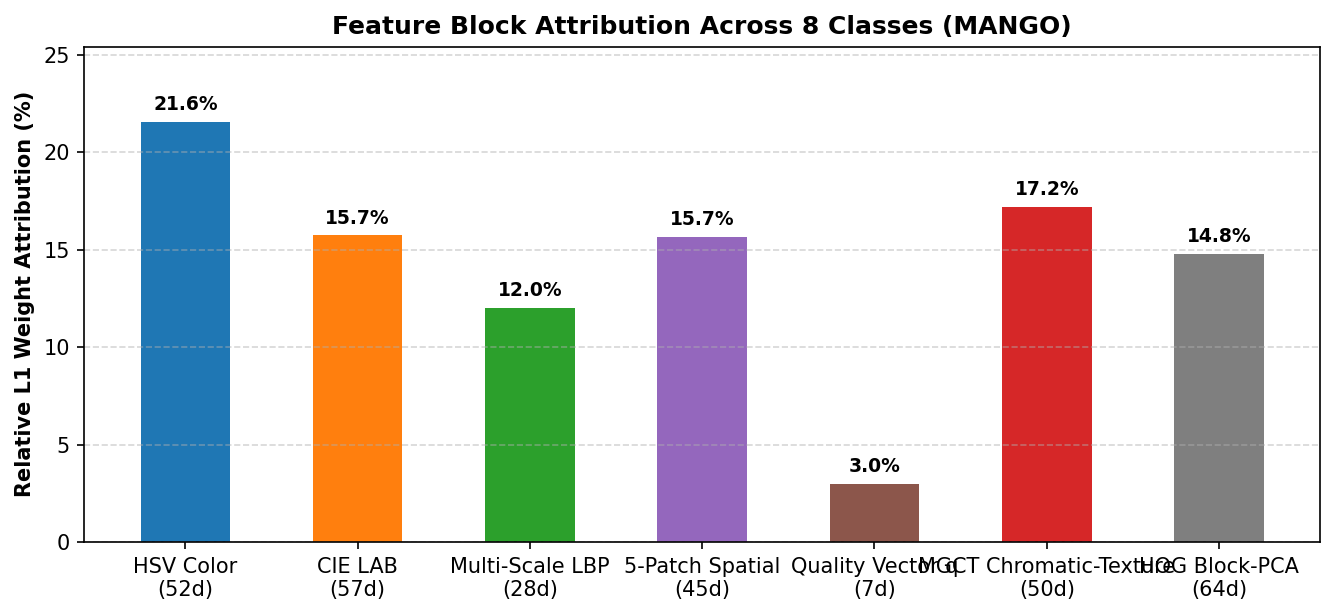


   BẢN TỔNG KẾT THỰC NGHIỆM (MANGO) — HÃY COPY TOÀN BỘ KHỐI NÀY GỬI LẠI
- Track đang chạy: MANGO | Số lớp: 8 (['Anthracnose', 'Bacterial_Canker', 'Cutting_Weevil', 'Die_Back', 'Gall_Midge', 'Healthy', 'Powdery_Mildew', 'Sooty_Mold'])
- Tổng số ảnh gốc đã kiểm toán: 4,000 ảnh

[1] TÓM TẮT KIỂM TOÁN RÒ RỈ & GẦN-TRÙNG (TABLE 1):
 Class ID       Class Name  Total Images  Unique Specimen Clusters (pHash<=6 | HSV cosine>=0.992)  Near-Duplicate / Aug-Mix Ratio (%) Dominant Resolution  Random-Split Test Leakage (%)
        0      Anthracnose           500                                                      352                                29.6             320x240                           39.0
        1 Bacterial_Canker           500                                                      275                                45.0             240x320                           39.0
        2   Cutting_Weevil           500                                                       31                   

,Track,Main dataset,External dataset configured,Main images after audit,Number of classes,CV-ranked ablation configuration,Best ablation Test Macro-F1,Validation-selected gate mode,Validation-selected gate Test Macro-F1,External validation completed,Artifacts directory,Status
0,MANGO,"MangoLeafBD Dataset (8 classes, ~4,000 images)",Raw Images of Five Class (Resized) / MLDID (5 ...,4000,8,M10. M9 + Block-PCA Compression (Proposed Stag...,0.9789,Confidence-Gated (tau=0.65),0.9836,True,/content/drive/MyDrive/Agri_EdgeAI_Research/MA...,SUCCESS


[MANGO PIPELINE COMPLETE] Summary saved to /content/drive/MyDrive/Agri_EdgeAI_Research/Mango_Overall_Summary.csv


In [ ]:
def run_one_track(cfg):
    """Run the full classical-vision protocol for one configured dataset."""
    track_name = cfg["track_name"]
    drive_folder = cfg["drive_folder"]
    track_dir = os.path.join(BASE_DRIVE_DIR, drive_folder)
    output_dir = os.path.join(track_dir, f"artifacts_{track_name}")
    cache_dir = os.path.join(output_dir, "feature_cache")
    local_ssd = os.path.join(LOCAL_SSD_BASE, drive_folder)
    os.makedirs(output_dir, exist_ok=True)
    os.makedirs(cache_dir, exist_ok=True)

    display(Markdown(f"# {track_name} — {cfg['main_dataset']}"))
    print(f"[TRACK START] {track_name}")
    print(f"[SOURCE ROLE] {cfg['main_source_role']}")
    print(f"[OUTPUT] {output_dir}")

    # Prepare both roles so each track can choose its source root explicitly.
    main_base = prepare_data_directory(
        os.path.join(track_dir, "main_data"),
        os.path.join(local_ssd, "main_data"),
        "MAIN",
    )
    external_base = prepare_data_directory(
        os.path.join(track_dir, "external_data"),
        os.path.join(local_ssd, "external_data"),
        "EXTERNAL",
    )
    bases = {
        "main_data": main_base,
        "external_data": external_base,
    }

    source_role = cfg["main_source_role"]
    source_base = bases.get(source_role)
    if source_base is None:
        raise FileNotFoundError(
            f"{track_name}: source role '{source_role}' is missing. "
            f"Check {os.path.join(track_dir, source_role)}."
        )

    main_root = _find_dataset_root_by_hints(
        source_base, cfg["main_root_hints"], required=True
    )

    external_root = None
    if cfg.get("external_root_hints") and external_base:
        # An external root is only for genuinely separate cross-dataset validation.
        external_root = _find_dataset_root_by_hints(
            external_base, cfg["external_root_hints"], required=False
        )
        if external_root is None:
            print(
                f"[EXTERNAL INFO] Root hints not found for {track_name}; "
                "Table 7 will be skipped rather than using a non-independent source."
            )

    manifest_path = os.path.join(
        output_dir, f"manifest_{track_name}_audited_v5.csv"
    )
    df_manifest, class_names = build_audited_manifest(
        main_root,
        track_name,
        manifest_path,
        output_dir=output_dir,
        seed=SEED,
    )

    expected = int(cfg["expected_class_count"])
    num_classes = len(class_names)
    if num_classes != expected:
        raise RuntimeError(
            f"{track_name}: detected {num_classes} classes; expected {expected}. "
            f"Detected labels: {class_names}. Review the selected dataset root."
        )
    display(pd.DataFrame({
        "Class ID": range(num_classes),
        "Canonical label": class_names,
    }))
    print(f"[MANIFEST READY] {len(df_manifest):,} images | {num_classes} classes")

    if RUN_BACKGROUND_SHORTCUT_AUDIT:
        df_shortcut_audit = run_background_shortcut_audit(
            df_manifest, track_name, output_dir=output_dir, seed=SEED
        )
    else:
        df_shortcut_audit = pd.DataFrame()
        print("[SKIP] Background shortcut audit disabled.")

    feature_cache_path = os.path.join(
        cache_dir, f"{track_name}_features_v8_mango.npz"
    )
    feat_data = extract_and_cache_all_variants(
        df_manifest, feature_cache_path
    )

    df_ablation = run_progressive_ablation(
        feat_data, track_name, output_dir=output_dir, seed=SEED
    )
    gated_system, df_gated_table = evaluate_confidence_gating(
        feat_data, track_name, output_dir=output_dir, seed=SEED
    )
    df_robustness = evaluate_multilevel_robustness(
        feat_data, gated_system, track_name, output_dir=output_dir, seed=SEED
    )
    df_fair_bench, stage_breakdown = run_end_to_end_benchmarks(
        df_manifest,
        num_classes,
        gated_system,
        track_name,
        output_dir,
        run_cnn=RUN_CNN_BENCHMARK,
        cnn_models=CNN_MODELS,
        cnn_epochs=CNN_EPOCHS,
        latency_sample_limit=CNN_LATENCY_SAMPLE_LIMIT,
        seed=SEED,
        external_root=external_root,
        class_names=class_names,
    )
    df_external_val = run_external_dataset_validation(
        external_root,
        feat_data,
        class_names,
        track_name,
        output_dir=output_dir,
        seed=SEED,
        source_view_mode=gated_system.selected_view_mode,
    )
    generate_figures_and_text_summary(
        track_name=track_name,
        output_dir=output_dir,
        num_classes=num_classes,
        class_names=class_names,
        df_manifest=df_manifest,
        gated_system=gated_system,
        df_shortcut_audit=df_shortcut_audit,
        df_ablation=df_ablation,
        df_gated_table=df_gated_table,
        df_robustness=df_robustness,
        df_fair_bench=df_fair_bench,
        stage_breakdown=stage_breakdown,
        df_external_val=df_external_val,
    )

    # Choose the ablation profile using Train Group-CV mean, not test Macro-F1.
    ranked_ablation = df_ablation.copy()
    if "3-Fold Train Group-CV F1" in ranked_ablation.columns:
        ranked_ablation["_cv_mean"] = pd.to_numeric(
            ranked_ablation["3-Fold Train Group-CV F1"]
            .astype(str).str.extract(r"([-+]?[0-9]*\.?[0-9]+)", expand=False),
            errors="coerce",
        )
        if ranked_ablation["_cv_mean"].notna().any():
            best_ablation = ranked_ablation.sort_values(
                "_cv_mean", ascending=False
            ).iloc[0]
        else:
            best_ablation = ranked_ablation.iloc[0]
    else:
        best_ablation = ranked_ablation.iloc[0]

    # Report the tau selected on validation. Do not select the threshold by test F1.
    selected_gate_label = (
        "Stage-1 LR Only" if gated_system.best_tau_gate <= 0.0
        else f"Confidence-Gated (tau={gated_system.best_tau_gate:.2f})"
    )
    selected_gate = df_gated_table[
        df_gated_table["Routing Mode"] == selected_gate_label
    ]
    best_gated = selected_gate.iloc[0] if not selected_gate.empty else None
    result = {
        "Track": track_name,
        "Main dataset": cfg["main_dataset"],
        "External dataset configured": cfg["external_dataset"],
        "Main images after audit": int(len(df_manifest)),
        "Number of classes": int(num_classes),
        "CV-ranked ablation configuration": best_ablation["Configuration"],
        "Best ablation Test Macro-F1": float(best_ablation["Test Macro-F1"]),
        "Validation-selected gate mode": (
            best_gated["Routing Mode"] if best_gated is not None else "n/a"
        ),
        "Validation-selected gate Test Macro-F1": (
            float(best_gated["Group-Split Macro-F1"])
            if best_gated is not None else float("nan")
        ),
        "External validation completed": bool(df_external_val is not None),
        "Artifacts directory": output_dir,
    }
    print(f"[TRACK COMPLETE] {track_name}")
    return result


# -----------------------------------------------------------------------------
# Single-track runner — this notebook focuses only on MANGO.
# -----------------------------------------------------------------------------
all_track_results = []
for index, track_cfg in enumerate(TRACKS, start=1):
    track_name = track_cfg["track_name"]
    print(
        f"\n{'=' * 96}\n"
        f"[MASTER] Track {index}/{len(TRACKS)}: {track_name}\n"
        f"{'=' * 96}"
    )
    try:
        track_result = run_one_track(track_cfg)
        track_result["Status"] = "SUCCESS"
    except Exception as exc:
        error_text = f"{type(exc).__name__}: {exc}"
        print(f"[TRACK FAILED] {track_name}: {error_text}")
        traceback.print_exc()
        error_path = os.path.join(
            BASE_DRIVE_DIR, f"ERROR_{track_name}.txt"
        )
        with open(error_path, "w", encoding="utf-8") as error_file:
            error_file.write(f"Track: {track_name}\n")
            error_file.write(f"Dataset: {track_cfg['main_dataset']}\n")
            error_file.write(f"Error: {error_text}\n")
        track_result = {
            "Track": track_name,
            "Main dataset": track_cfg["main_dataset"],
            "Status": "FAILED",
            "Error": error_text,
            "Artifacts directory": os.path.join(
                BASE_DRIVE_DIR,
                track_cfg["drive_folder"],
                f"artifacts_{track_name}",
            ),
        }
    all_track_results.append(track_result)
    gc.collect()

summary_df = pd.DataFrame(all_track_results)
display(summary_df)
summary_path = os.path.join(BASE_DRIVE_DIR, "Mango_Overall_Summary.csv")
summary_df.to_csv(summary_path, index=False)
print(f"[MANGO PIPELINE COMPLETE] Summary saved to {summary_path}")


## 17. Output cuối cùng

Kết quả được lưu trong:
`/content/drive/MyDrive/Agri_EdgeAI_Research/MANGO/artifacts_MANGO/`

Các file chính:
- `manifest_MANGO_audited_v5.csv`
- `Table1_Dataset_Leakage_and_Group_Audit.csv`
- `Table2_Background_Shortcut_Audit.csv`
- `Table3_Progressive_Ablation_Study.csv`
- `Table4_Confidence_Gated_and_Calibration.csv`
- `Table5_MultiSeverity_Robustness.csv`
- `Table6_Fair_EndToEnd_CPU_Benchmark.csv`
- `Table7_External_Dataset_Validation.csv` nếu có đủ nhãn chung
- Hình attribution, bản tổng kết Markdown/CSV và cache `v8`.

Bảng tổng kết đơn track nằm tại `Agri_EdgeAI_Research/MANGO/Mango_Overall_Summary.csv`.

**Trước khi viết paper:** chạy lại từ đầu, kiểm tra class counts, log lỗi và trạng thái benchmark. Báo cáo Group-Split là kết quả chính; Random-Split là tham chiếu có rủi ro leakage; CORAL là transductive. Không dùng các con số lịch sử trong HTML như kết quả của phiên v5.
